# Gaussian-probe thickness and Drude-injection sweep

Prepare **six** SiO₂ scenarios: thicknesses **10 nm, 1 µm, 5 µm**, each with
`del_omega_D = [100.0, 250.0]` rad/ps and fixed `gamma_D0 = 150.0` ps⁻¹.
The pulse parameters are unchanged: a **166 THz Gaussian probe, 30 fs intensity-envelope FWHM, amplitude 0.1, zero phase**, and a **1.5 eV Gaussian pump, 3 fs intensity-envelope FWHM, amplitude 1, zero phase**.
The Drude increase remains globally normalized $\sqrt{\int E_{\rm pump}^8\,dt}$ with no recombination or probe feedback. Frequency/rate values use the existing solver convention, without an extra $2\pi$ factor.

The **2 nm grid**, 30 µm simulation domain, 15 µm sample-center convention, 2.5 µm source position, 3 µm probe offsets from the sample faces, silica poles, absorbing boundaries, interpolation/cache settings, padding/margins, and 151-point dense delay scan plus echo/end-point samples are retained. Geometry, propagation duration, and overlap bounds are recalculated for each thickness using those same rules. The 10 nm film is exactly **five cells** thick: pump recording is every cell there so cubic field reconstruction has enough samples; the other thicknesses retain every-ninth-cell recording.

**To run later:** save the notebook, then use **Run All**, or run the configuration cell followed directly by **Run the complete thickness sweep**. The intervening stage cells are guarded by `RUN_SETUP_CELLS = False` and do not run individually by default; the runner executes their saved code in a fresh namespace for each thickness. To inspect one thickness interactively, set `THICKNESS_NM`/`OUTPUT_ROOT` in the configuration cell and enable `RUN_SETUP_CELLS`, then run the stage cells. Run All normally leaves that flag `False` to avoid duplicate work.

Each thickness gets its own propagated pump, injection cache, no-injection reference, and two delay scans. After both scans, the runner saves **both raw and continuum-normalized integrated and single-lobe plots**, in separate directories. The continuum means map to **1 at the start and 0 at the end**. Standalone saved-data plotting remains available at the end and never runs FDTD.

All new files go beneath:
`output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/`
with `thickness_10nm/`, `thickness_1000nm/`, and `thickness_5000nm/` subdirectories. Each contains `pump_3fs_1p5eV_sio2/`, `shared_injection/`, `del_omega_D_100_rad_per_ps/`, `del_omega_D_250_rad_per_ps/`, and `analysis_plots/{raw,continuum_normalized}/`. Previous 12.82 µm outputs are separate.


In [1]:
from pathlib import Path
import sys, os, json, hashlib, time, shutil
package_root = next((candidate for root in (Path.cwd(), *Path.cwd().parents)
                     for candidate in (root, root / "lightmatter")
                     if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None)
if package_root is None:
    raise FileNotFoundError("Run from inside the lightmatter workspace.")
sys.path.insert(0, str(package_root / "src"))
import numba
numba.set_num_threads(1)

MATERIAL_THICKNESSES_NM = [10.0, 1000.0, 5000.0]
DEL_OMEGA_D_VALUES = [100.0, 250.0]
FIXED_GAMMA_D0 = 150.0
SWEEP_ROOT = package_root / "output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250"
RUN_SETUP_CELLS = False  # Keep False for Run All / the complete-sweep runner.
# Only used when manually running the guarded stages for one thickness.
THICKNESS_NM = MATERIAL_THICKNESSES_NM[0]
OUTPUT_ROOT = SWEEP_ROOT / f"thickness_{THICKNESS_NM:g}nm"
print("Planned thicknesses (nm):", MATERIAL_THICKNESSES_NM)
print("Planned ΔωD values (rad/ps):", DEL_OMEGA_D_VALUES)
print("Sweep output:", SWEEP_ROOT)


Planned thicknesses (nm): [10.0, 1000.0, 5000.0]
Planned ΔωD values (rad/ps): [100.0, 250.0]
Sweep output: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250


## Propagated pump stage
The runner regenerates the pump for each thickness; pump propagation and injection are never reused across different geometries. These guarded stage cells execute automatically inside the complete-sweep runner below. They are skipped individually unless `RUN_SETUP_CELLS=True`.

In [2]:
if RUN_SETUP_CELLS:
    from pathlib import Path
    import json

    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.constants import elementary_charge, h
    from lightmatter.fdtd_revised_sio2 import (
        FDTDParams, PulseParams, MaterialParamsTD, run_simulation,
        SIO2_BACKGROUND_DEL_EPS_DEFAULT, SIO2_BACKGROUND_LAMBDA0_UM_DEFAULT,
    )
    from lightmatter.io import save_simulation_run
    from lightmatter.units import C0, UNIT_T, UNIT_E

    # Resolve output correctly from the workspace, package, or notebook directory.
    pump_search_roots = (Path.cwd(), *Path.cwd().parents)
    pump_package_root = next(
        (candidate for root in pump_search_roots
         for candidate in (root, root / "lightmatter")
         if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()),
        None,
    )
    if pump_package_root is None:
        raise FileNotFoundError("Run this section from inside the lightmatter workspace.")
    pump_output_dir = OUTPUT_ROOT / "pump_3fs_1p5eV_sio2"

    PUMP_INTENSITY_FWHM_FS = 3.0
    PUMP_ENERGY_EV = 1.5
    PUMP_PROBE_EVERY = 9       # Default recording spacing; adapted below only for very thin films.
    pump_f0 = PUMP_ENERGY_EV * elementary_charge / h * UNIT_T  # cycles/ps
    pump_tau = PUMP_INTENSITY_FWHM_FS * 1e-3 / (2 * np.sqrt(np.log(2)))
    pump_pulse = PulseParams(
        E0=1.0, f0=pump_f0, t0=10e-3, tau=pump_tau, phase=0.0, type="gaussian",
    )

    # Same geometry as the experimental scan; 2 nm cells resolve the optical pump.
    # dt also resolves the fastest equilibrium UV pole (omega_max*dt < 0.3).
    pump_dz = 20.0                                      # Angstrom
    pump_dt = 0.99 * pump_dz / C0                        # ps
    pump_Nz = int(round(30e4 / pump_dz))
    pump_src_i = int(round(2.5e4 / pump_dz))
    pump_material_cells = int(round(THICKNESS_NM * 10.0 / pump_dz))
    if pump_material_cells < 4 or not np.isclose(pump_material_cells*pump_dz, THICKNESS_NM*10.0):
        raise ValueError("Thickness must align to the 2 nm grid and contain at least four cells for cubic reconstruction.")
    # At least four recorded field traces are needed by the unchanged cubic interpolation.
    PUMP_PROBE_EVERY = min(PUMP_PROBE_EVERY, max(1, (pump_material_cells-1)//3))
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    print(f"Number of material cells: {pump_material_cells}")
    pump_metal_i0 = int(round(15e4 / pump_dz)) - pump_material_cells // 2
    pump_metal_i1 = pump_metal_i0 + pump_material_cells
    pump_probe_r_i = pump_metal_i0 - int(round(3e4 / pump_dz))
    pump_probe_t_i = pump_metal_i1 + int(round(3e4 / pump_dz))

    print(f"Last probe id: {np.arange(pump_metal_i0, pump_metal_i1, PUMP_PROBE_EVERY, dtype=np.int64)[-1]}, last SiO2 cell:{pump_metal_i1}")

    # Estimate group delay from the same background used by the solver.
    pump_background_B = np.array(SIO2_BACKGROUND_DEL_EPS_DEFAULT)
    pump_background_lambda_um = np.array(SIO2_BACKGROUND_LAMBDA0_UM_DEFAULT)
    pump_lambda_um = C0 * 1e-4 / pump_f0
    pump_resonance_sq = pump_background_lambda_um**2
    pump_epsilon = 1 + np.sum(
        pump_background_B * pump_lambda_um**2 / (pump_lambda_um**2 - pump_resonance_sq)
    )
    pump_n = np.sqrt(pump_epsilon)
    pump_deps_dlambda = np.sum(
        -2 * pump_background_B * pump_lambda_um * pump_resonance_sq
        / (pump_lambda_um**2 - pump_resonance_sq)**2
    )
    pump_ng = pump_n - pump_lambda_um * pump_deps_dlambda / (2 * pump_n)
    pump_transit_ps = (
        (pump_metal_i0 - pump_src_i) * pump_dz
        + pump_ng * pump_material_cells * pump_dz
        + (pump_probe_t_i - pump_metal_i1) * pump_dz
    ) / C0
    # Record the main transmitted pulse plus 30 fs; later internal echoes need longer runs.
    pump_duration_ps = pump_pulse.t0 + 6 * pump_tau + pump_transit_ps + 30e-3
    pump_Nt = int(np.ceil(pump_duration_ps / pump_dt)) + 1
    pump_time_ps = np.arange(pump_Nt) * pump_dt
    pump_material_z_A = np.arange(pump_metal_i0, pump_metal_i1) * pump_dz
    pump_params = FDTDParams(
        Nz=pump_Nz, Nt=pump_Nt, dz=pump_dz, dt=pump_dt,
        src_i=pump_src_i, probe_t_i=pump_probe_t_i, probe_r_i=pump_probe_r_i,
        metal_i0=pump_metal_i0, metal_i1=pump_metal_i1,
        npml=int(round(1e4 / pump_dz)), snap_every=0,
    )
    pump_material = MaterialParamsTD.from_static(
        Nt=pump_Nt, omega_D=0.0, gamma_D=0.0,
        omega_L=0.0, gamma_L=0.0, del_eps=0.0, eps_inf=1.0,
    )
    pump_source_field = (
        pump_pulse.E0 * np.cos(2 * np.pi * pump_f0 * (pump_time_ps - pump_pulse.t0) + pump_pulse.phase)
        * np.exp(-0.5 * ((pump_time_ps - pump_pulse.t0) / pump_tau)**2)
    )
    pump_nprobes = len(range(pump_metal_i0, pump_metal_i1, PUMP_PROBE_EVERY))
    print(f"Carrier: {pump_f0:.6f} THz, wavelength: {pump_lambda_um:.6f} um")
    print(f"Intensity FWHM: {PUMP_INTENSITY_FWHM_FS:g} fs; tau: {pump_tau*1e3:.6f} fs")
    print(f"Grid: {pump_Nz} cells, {pump_Nt} steps, dt={pump_dt*1e3:.6f} fs")
    print(f"Material probes: {pump_nprobes}; field storage: {8*pump_Nt*pump_nprobes/2**20:.1f} MiB")
    print(f"Output directory: {pump_output_dir}")

In [3]:
if RUN_SETUP_CELLS:
    # Run this cell to simulate and save the pump. Re-running overwrites this run folder.
    pump_E_t, pump_E_r, pump_snaps_t, pump_snaps_E, pump_probes = run_simulation(
        pump_params, pump_pulse, pump_material,
        method="sio2_background",
        material_probe_every=PUMP_PROBE_EVERY,
    )
    if not all(np.all(np.isfinite(a)) for a in (pump_E_t, pump_E_r, pump_probes["E"])):
        raise RuntimeError("Pump simulation produced non-finite fields; check the grid/material parameters.")

    # Preserve the project's standard info.json + data.npz format.
    save_simulation_run(
        folder=str(pump_output_dir), params=pump_params, pulse=pump_pulse,
        material=pump_material, E_t=pump_E_t, E_r=pump_E_r,
        snaps_t=pump_snaps_t, snaps_E=pump_snaps_E,
    )
    # Extra time-resolved material probes, with explicit axes and units.
    np.savez_compressed(
        pump_output_dir / "pump_material_probes.npz",
        E=pump_probes["E"], t_ps=pump_probes["t"],
        z_A=pump_probes["z"], z_um=pump_probes["z"]*1e-4,
        cell_indices=pump_probes["indices"], source_E=pump_source_field,
    )
    pump_metadata = {
        "material_thickness_nm": THICKNESS_NM,
        "material_cells": pump_material_cells,
        "method": "sio2_background",
        "intensity_envelope_fwhm_fs": PUMP_INTENSITY_FWHM_FS,
        "carrier_energy_eV": PUMP_ENERGY_EV,
        "carrier_frequency_THz": pump_f0,
        "carrier_wavelength_um": pump_lambda_um,
        "field_unit": "code units",
        "field_unit_V_per_m": UNIT_E,
        "source_amplitude_note": "Unit soft-source amplitude; no experimental intensity calibration",
        "probe_every_cells": PUMP_PROBE_EVERY,
        "probe_field_axes": ["time", "material_probe"],
        "material_parameter_axes": ["time", "material_cell (if 2D)"],
        "sample_time_convention": "Post-update/source fields labelled by source time n*dt",
        "background_del_eps": pump_background_B.tolist(),
        "background_lambda0_um": pump_background_lambda_um.tolist(),
        "background_gamma_per_ps": [0.0] * len(pump_background_B),
    }
    (pump_output_dir / "pump_metadata.json").write_text(json.dumps(pump_metadata, indent=2))
    print(f"Saved fields, material parameters, probes and metadata to {pump_output_dir}")
    # Reload probes later with np.load(pump_output_dir / "pump_material_probes.npz").

In [4]:
if RUN_SETUP_CELLS:
    # Show and save the pump propagation. Thin time samples only for plotting.
    pump_plot_step = max(1, pump_Nt // 2000)
    pump_fig, pump_axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    pump_axes[0].plot(pump_time_ps*1e3, pump_source_field, label="Soft source")
    pump_axes[0].plot(pump_time_ps*1e3, pump_E_t, label="Transmitted probe")
    pump_axes[0].set(xlabel="Simulation time (fs)", ylabel="E (code units)")
    pump_axes[0].legend()
    pump_axes[0].grid(alpha=0.25)
    pump_map = pump_axes[1].pcolormesh(
        pump_probes["z"]*1e-4, pump_probes["t"][::pump_plot_step]*1e3,
        pump_probes["E"][::pump_plot_step], shading="auto", cmap="RdBu_r",
        vmin=-np.max(np.abs(pump_probes["E"])), vmax=np.max(np.abs(pump_probes["E"])),
    )
    pump_axes[1].set(xlabel="Position in simulation domain (um)", ylabel="Simulation time (fs)")
    pump_fig.colorbar(pump_map, ax=pump_axes[1], label="E (code units)")
    pump_fig.suptitle(f"3 fs intensity-FWHM, 1.5 eV pump through {THICKNESS_NM:g} nm SiO2")
    pump_fig.savefig(pump_output_dir / "pump_propagation.png", dpi=180)
    plt.show()

## Analytic Gaussian probe and injection configuration
The pump response is unchanged:
$$
\omega_D(z,t;\Delta)=\Delta\omega_D\sqrt{\frac{\int^{t-s(\Delta)} E_{\rm pump}(z,t')^8dt'}{\max_{z'}\int^{t_{\rm end}} E_{\rm pump}(z',t')^8dt'}}.
$$
Cubic interpolation reconstructs **fields before taking their eighth power**. Integration uses the original pump timestep, followed by the existing 0.02 fs response cache and one global normalization. There is no recombination or probe feedback.

The saved delay is `Δ = probe peak − pump peak` at the sample front; **positive means pump first**. Plots retain this sign. Reference overlays use `Δ = transmitted reference peak − waveform time`; their top axis shows the physical waveform time relative to its peak. This is a timing guide for the distributed interaction, with no fitted time shift.

In [5]:
if RUN_SETUP_CELLS:
    # Probe configuration and saved pump inputs
    from pathlib import Path
    from dataclasses import asdict
    import json
    import warnings

    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.integrate import cumulative_trapezoid, trapezoid
    from scipy.signal import hilbert
    from tqdm.auto import tqdm
    from lightmatter.fdtd_revised_sio2 import FDTDParams, PulseParams, MaterialParamsTD, run_simulation
    from lightmatter.units import C0, UNIT_T

    package_root = next(
        (candidate for root in (Path.cwd(), *Path.cwd().parents)
         for candidate in (root, root / "lightmatter")
         if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None,
    )
    if package_root is None:
        raise FileNotFoundError("Run this notebook from inside the lightmatter workspace.")
    PUMP_RUN_DIR = pump_output_dir
    SPATIAL_INTERPOLATION = "cubic"     # "cubic", "linear", "retarded", or "none"
    PROBE_DZ_A = None                  # None reuses the saved pump grid (2 nm)
    INJECTION_CACHE_DT_FS = 0.02       # integrate at original pump dt; then cache sqrt(cumulative E^8)
    SPATIAL_BLOCK_CELLS = 32          # bounds temporary field/interpolation arrays

    SOURCE_PREPAD_FS = 20.0
    POST_RECORD_MARGIN_FS = 30.0       # minimum; also allow echoes and Drude decay
    MIN_INTERNAL_ROUND_TRIPS = 0.5     # this is also a safety feature, but I don't care too much about internal reflections
    MIN_DRUDE_DAMPING_TIMES = 1.0      # this is probably not theoretically enough, but this scales very badly

    ENERGY_TAIL_FRACTION = 1e-3        # central 99.8% probe energy / local pump sqrt(integral E^8) response
    SCAN_MARGIN_FS = 20.0
    N_DELAYS = 151                    # dense samples across the main-pulse overlap
    ECHO_DELAY_STEP_FS = 30.0          # coarser outer scan covering weaker internal echoes
    PROBE_OCCUPANCY_TAIL_FRACTION = 1e-3
    PROBE_TIMING_EVERY_CELLS = 32     # sparse probes in the unpumped control, including both ends
    REPRESENTATIVE_DELAY_FS = 0.0
    CARRIER_FREQUENCY_THz = 166.0
    TAIL_CHECK_FS = 10.0
    TAIL_ENERGY_TOLERANCE = 1e-4
    INTERPOLATION_RESPONSE_TOLERANCE = 0.01

    ########---------------- TIME-VARYING DRUDE PARAMETERS ----------------########
    omega_D0 = 0.0
    del_omega_D = DEL_OMEGA_D_VALUES[0]
    gamma_D0 = FIXED_GAMMA_D0
    ########---------------- ----------------------------- ----------------########

    with (PUMP_RUN_DIR / "info.json").open() as stream:
        saved_pump_info = json.load(stream)
    with (PUMP_RUN_DIR / "pump_metadata.json").open() as stream:
        saved_pump_metadata = json.load(stream)
    saved_pump_params = FDTDParams(**saved_pump_info["fdtd_params"])
    with np.load(PUMP_RUN_DIR / "pump_material_probes.npz") as archive:
        pump_record_t = archive["t_ps"]
        pump_record_z = archive["z_A"]
        pump_record_E = archive["E"]
        pump_record_source = archive["source_E"]
        pump_record_indices = archive["cell_indices"]
    if (pump_record_t.ndim != 1 or pump_record_z.ndim != 1
            or pump_record_E.shape != (pump_record_t.size, pump_record_z.size)
            or pump_record_source.shape != pump_record_t.shape
            or pump_record_t.size < 3 or pump_record_z.size < 1):
        raise ValueError("Pump arrays must be t:(Nt,), z:(Nprobes,), E:(Nt,Nprobes), source:(Nt,).")
    if not all(np.all(np.isfinite(a)) for a in (pump_record_t, pump_record_z, pump_record_E, pump_record_source)):
        raise ValueError("Saved pump arrays contain non-finite values.")
    if np.any(np.diff(pump_record_t) <= 0) or np.any(np.diff(pump_record_z) <= 0):
        raise ValueError("Pump time and probe positions must be strictly increasing.")
    if (pump_record_t.size != saved_pump_params.Nt
            or not np.allclose(pump_record_t, np.arange(saved_pump_params.Nt)*saved_pump_params.dt)
            or not np.array_equal(pump_record_z, pump_record_indices*saved_pump_params.dz)
            or np.any(pump_record_indices < saved_pump_params.metal_i0)
            or np.any(pump_record_indices >= saved_pump_params.metal_i1)):
        raise ValueError("Pump probe axes disagree with the saved geometry/timestep.")
    if not np.any(pump_record_source):
        raise ValueError("The saved incident pump waveform is zero.")
    if SPATIAL_INTERPOLATION not in ("none", "linear", "cubic", "retarded"):
        raise ValueError("Unknown spatial interpolation mode.")
    if not (0 < ENERGY_TAIL_FRACTION < 0.5) or INJECTION_CACHE_DT_FS <= 0:
        raise ValueError("Require 0 < ENERGY_TAIL_FRACTION < 0.5 and a positive cache timestep.")
    if not isinstance(N_DELAYS, int) or N_DELAYS < 3 or del_omega_D <= 0 or gamma_D0 < 0:
        raise ValueError("Require at least three delays, positive del_omega_D, and nonnegative damping.")
    if ECHO_DELAY_STEP_FS <= 0 or not (0 < PROBE_OCCUPANCY_TAIL_FRACTION < 0.5):
        raise ValueError("Require positive echo delay spacing and a valid probe occupation tail fraction.")
    if not isinstance(PROBE_TIMING_EVERY_CELLS, int) or PROBE_TIMING_EVERY_CELLS < 1:
        raise ValueError("PROBE_TIMING_EVERY_CELLS must be a positive integer.")
    if MIN_INTERNAL_ROUND_TRIPS < 0 or MIN_DRUDE_DAMPING_TIMES < 0:
        raise ValueError("Echo and damping-time allowances must be nonnegative.")
    if not isinstance(SPATIAL_BLOCK_CELLS, int) or SPATIAL_BLOCK_CELLS < 1:
        raise ValueError("SPATIAL_BLOCK_CELLS must be a positive integer.")
    if SOURCE_PREPAD_FS < 0 or POST_RECORD_MARGIN_FS <= 0 or SCAN_MARGIN_FS < 0:
        raise ValueError("Padding/margins must be nonnegative, with a positive recording margin.")


    # Truncate only at +/- six field-envelope standard deviations (amplitude ~1.5e-8).
    PROBE_INTENSITY_FWHM_FS = 30.0
    PROBE_PHASE = 0.0
    E0 = 0.1
    probe_tau_ps = PROBE_INTENSITY_FWHM_FS*1e-3/(2*np.sqrt(np.log(2)))
    probe_half_samples = int(np.ceil(6*probe_tau_ps/saved_pump_params.dt))
    waveform_time_rel_ps = np.arange(2*probe_half_samples+1)*saved_pump_params.dt
    waveform_time_rel_fs = waveform_time_rel_ps*1e3
    probe_incident_peak_rel_ps = waveform_time_rel_ps[probe_half_samples]
    probe_sample_dt_fs = saved_pump_params.dt*1e3

    def gaussian_probe(relative_time_ps):
        offset = np.asarray(relative_time_ps)-probe_incident_peak_rel_ps
        return E0*np.cos(2*np.pi*CARRIER_FREQUENCY_THz*offset+PROBE_PHASE)*np.exp(-0.5*(offset/probe_tau_ps)**2)

    reference_field = gaussian_probe(waveform_time_rel_ps)
    pump_incident_peak_source_ps = pump_record_t[np.argmax(np.abs(pump_record_source))]
    assert np.argmax(abs(reference_field)) == probe_half_samples
    assert np.isclose(np.exp(-(15e-3/probe_tau_ps)**2), 0.5)
    assert np.isclose((saved_pump_params.metal_i1-saved_pump_params.metal_i0)*saved_pump_params.dz/10.0, THICKNESS_NM)
    print(f"Probe: {CARRIER_FREQUENCY_THz:g} THz; intensity FWHM {PROBE_INTENSITY_FWHM_FS:g} fs; peak {E0:g}")
    fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    relative_fs = (waveform_time_rel_ps-probe_incident_peak_rel_ps)*1e3
    ax.plot(relative_fs, reference_field, label="Analytic Gaussian E")
    ax.plot(relative_fs, E0*np.exp(-0.5*((waveform_time_rel_ps-probe_incident_peak_rel_ps)/probe_tau_ps)**2),
            "--", label="Field envelope")
    ax.set(xlabel="Time relative to incident probe peak (fs)", ylabel="E (code units)")
    ax.legend(); ax.grid(alpha=0.25)
    fig.savefig(OUTPUT_ROOT / "gaussian_probe_source.png", dpi=180)
    plt.show()

In [6]:
if RUN_SETUP_CELLS:
    # Numerical helpers: spatial fields, cumulative integrals, and time shifts

    def silica_indices(frequency_THz):
        """Phase/group indices of the saved lossless equilibrium background."""
        f = np.asarray(frequency_THz, dtype=float)
        if np.any(f <= 0):
            raise ValueError("Frequency must be positive.")
        B = np.asarray(saved_pump_metadata["background_del_eps"])
        resonances = np.asarray(saved_pump_metadata["background_lambda0_um"])**2
        wavelength = C0 * 1e-4 / f
        denom = wavelength[..., None]**2 - resonances
        eps = 1 + np.sum(B * wavelength[..., None]**2 / denom, axis=-1)
        deriv = np.sum(-2*B*wavelength[..., None]*resonances/denom**2, axis=-1)
        if not np.all(np.isfinite(eps)) or np.any(eps <= 0):
            raise ValueError("Selected frequencies are outside the transparent silica band.")
        n = np.sqrt(eps)
        ng = n - wavelength * deriv / (2*n)
        return n, ng


    def pump_injection_response(field, time, axis=0):
        """Unnormalized Drude increase: sqrt(integral E^8 dt), with zero initial value."""
        return np.sqrt(cumulative_trapezoid(np.asarray(field)**8, time, axis=axis, initial=0))


    def integral_quantiles(time, cumulative, quantiles):
        """Times at given fractions of a nondecreasing integral or injection response."""
        if cumulative[-1] <= 0:
            return np.full(len(quantiles), np.nan)
        return np.interp(np.asarray(quantiles)*cumulative[-1], cumulative, time)


    def interpolate_pump_fields(time, positions, fields, targets, mode="cubic",
                                phase_index=None, group_index=None, carrier_THz=None):
        """Return E(time, target); call on spatial blocks to bound working memory."""
        time, positions, targets = map(lambda x: np.asarray(x, dtype=float), (time, positions, targets))
        fields = np.asarray(fields)
        if (time.ndim != 1 or positions.ndim != 1 or targets.ndim != 1
                or fields.shape != (time.size, positions.size)
                or time.size < 2 or positions.size == 0
                or np.any(np.diff(time) <= 0) or np.any(np.diff(positions) <= 0)
                or not all(np.all(np.isfinite(a)) for a in (time, positions, targets))):
            raise ValueError("Invalid field interpolation dimensions/coordinates.")
        if mode == "none":
            idx = np.searchsorted(positions, targets)
            if np.any(idx >= positions.size) or not np.allclose(positions[np.minimum(idx, positions.size-1)], targets, rtol=0, atol=1e-8):
                raise ValueError("Interpolation is disabled: pump probes must cover every requested cell.")
            return fields[:, idx].copy()
        if mode not in ("linear", "cubic", "retarded"):
            raise ValueError("Unknown interpolation mode.")
        count = 4 if mode == "cubic" else 2
        if positions.size < count:
            raise ValueError(f"{mode} interpolation needs at least {count} recorded probes.")
        if np.any(targets < positions[0] - (positions[1]-positions[0])) or np.any(targets > positions[-1] + (positions[-1]-positions[-2])):
            raise ValueError("Refusing extrapolation by more than one probe spacing.")
        starts = np.clip(np.searchsorted(positions, targets) - count//2, 0, positions.size-count)
        ids = starts[:, None] + np.arange(count)[None, :]
        x = positions[ids]
        weights = np.ones_like(x)
        for j in range(count):
            for k in range(count):
                if k != j:
                    weights[:, j] *= (targets-x[:, k])/(x[:, j]-x[:, k])
        out = np.zeros((time.size, targets.size))
        if mode != "retarded":
            for j in range(count):
                out += fields[:, ids[:, j]] * weights[:, j]
            return out
        if (phase_index is None or group_index is None or carrier_THz is None
                or min(phase_index, group_index, carrier_THz) <= 0):
            raise ValueError("Retarded interpolation requires positive phase/group indices and carrier frequency.")
        # Pad both ends before Hilbert transformation to reduce periodic edge artifacts.
        selected, inverse = np.unique(ids, return_inverse=True)
        analytic = hilbert(np.pad(fields[:, selected], ((time.size, time.size), (0, 0))), axis=0)[time.size:2*time.size]
        lookup = inverse.reshape(ids.shape)
        for col, target in enumerate(targets):
            for j in range(count):
                displacement = target - x[col, j]
                shifted_time = time - group_index*displacement/C0
                a = analytic[:, lookup[col, j]]
                shifted = (np.interp(shifted_time, time, a.real, left=0, right=0)
                           + 1j*np.interp(shifted_time, time, a.imag, left=0, right=0))
                phase = 2*np.pi*carrier_THz*(group_index-phase_index)*displacement/C0
                out[:, col] += weights[col, j] * np.real(shifted*np.exp(1j*phase))
        return out


    def resample_cumulative(time, profile, query, out=None, scale=1.0, baseline=0.0):
        """Linear time interpolation with zero/terminal plateaus, in row blocks."""
        time, query = np.asarray(time), np.asarray(query)
        if (time.ndim != 1 or query.ndim != 1 or profile.ndim != 2
                or profile.shape[0] != time.size or time.size < 2
                or np.any(np.diff(time) <= 0) or not np.all(np.isfinite(query))):
            raise ValueError("Invalid cumulative-profile dimensions or times.")
        if out is None:
            out = np.empty((query.size, profile.shape[1]), dtype=np.float64)
        if out.shape != (query.size, profile.shape[1]) or out.dtype != np.float64:
            raise ValueError("Output must be float64 with shape (Nquery, Nmaterial).")
        for lo in range(0, query.size, 256):
            hi = min(lo+256, query.size)
            index = np.clip(np.searchsorted(time, query[lo:hi], side="right")-1, 0, time.size-2)
            fraction = np.clip((query[lo:hi]-time[index])/(time[index+1]-time[index]), 0, 1)
            out[lo:hi] = baseline + scale*((1-fraction[:, None])*profile[index] + fraction[:, None]*profile[index+1])
        return out

In [7]:
if RUN_SETUP_CELLS:
    # Geometry and interpolation cross-validation (no FDTD runs here)
    pump_phase_index, pump_group_index = map(float, silica_indices(saved_pump_metadata["carrier_frequency_THz"]))
    source_prepad = SOURCE_PREPAD_FS*1e-3
    dz = saved_pump_params.dz if PROBE_DZ_A is None else float(PROBE_DZ_A)
    if not np.isfinite(dz) or dz <= 0:
        raise ValueError("PROBE_DZ_A must be positive and finite.")
    dt = min(0.99*dz/C0, saved_pump_params.dt)
    L = saved_pump_params.Nz * saved_pump_params.dz
    Nz = int(round(L/dz))

    def aligned_index(position_A):
        index = int(round(position_A/dz))
        if not np.isclose(index*dz, position_A, atol=1e-8, rtol=0):
            raise ValueError("The chosen probe grid must align with the saved sample/source/probes.")
        return index

    src_i = aligned_index(saved_pump_params.src_i*saved_pump_params.dz)
    probe_r_i = aligned_index(saved_pump_params.probe_r_i*saved_pump_params.dz)
    probe_t_i = aligned_index(saved_pump_params.probe_t_i*saved_pump_params.dz)
    metal_i0 = aligned_index(saved_pump_params.metal_i0*saved_pump_params.dz)
    metal_i1 = aligned_index(saved_pump_params.metal_i1*saved_pump_params.dz)
    material_z_A = np.arange(metal_i0, metal_i1)*dz
    metal_cells = material_z_A.size
    src_pos, probe_r_pos, probe_t_pos = np.array([src_i, probe_r_i, probe_t_i])*dz
    sample_front_pos, sample_back_pos = np.array([metal_i0, metal_i1])*dz
    thickness = sample_back_pos-sample_front_pos
    source_to_front_time = (sample_front_pos-src_pos)/C0
    back_to_transmission_probe_time = (probe_t_pos-sample_back_pos)/C0
    pump_incident_peak_front_ps = pump_incident_peak_source_ps + (
        sample_front_pos-saved_pump_params.src_i*saved_pump_params.dz)/C0
    probe_incident_peak_front_ps = source_prepad + probe_incident_peak_rel_ps + source_to_front_time


    def pump_time_shift_ps(delay_fs):
        return probe_incident_peak_front_ps - float(delay_fs)*1e-3 - pump_incident_peak_front_ps

    interpolation_errors = {}
    # Leave out sparse interior nodes simultaneously. Retain their four neighbours.
    withheld = np.unique(np.linspace(2, pump_record_z.size-3, min(24, max(0, (pump_record_z.size-4)//5))).astype(int))
    if withheld.size and pump_record_z.size >= 8:
        keep = np.ones(pump_record_z.size, dtype=bool)
        keep[withheld] = False
        truth = pump_record_E[:, withheld]
        truth_response = pump_injection_response(truth, pump_record_t)[-1]
        for mode in ("linear", "cubic", "retarded"):
            estimate = interpolate_pump_fields(
                pump_record_t, pump_record_z[keep], pump_record_E[:, keep], pump_record_z[withheld], mode,
                pump_phase_index, pump_group_index, saved_pump_metadata["carrier_frequency_THz"],
            )
            relative_field = np.linalg.norm(estimate-truth, axis=0)/np.maximum(np.linalg.norm(truth, axis=0), np.finfo(float).tiny)
            relative_response = abs(pump_injection_response(estimate, pump_record_t)[-1]/np.maximum(truth_response, np.finfo(float).tiny)-1)
            interpolation_errors[mode] = {"max_field_relative_L2": float(relative_field.max()), "max_sqrt_E8_response_relative_error": float(relative_response.max())}
            print(f"{mode:8s}: held-out field L2 error <= {relative_field.max():.3%}; sqrt(integral E^8) response error <= {relative_response.max():.3%}")
        if SPATIAL_INTERPOLATION != "none" and interpolation_errors[SPATIAL_INTERPOLATION]["max_sqrt_E8_response_relative_error"] > INTERPOLATION_RESPONSE_TOLERANCE:
            raise ValueError("Chosen interpolation failed the sqrt(integral E^8) response tolerance. Use finer pump probes or explicitly revise the tolerance after checking convergence.")
    else:
        warnings.warn("Too few pump probes for the held-out accuracy check; verify spatial convergence separately.")
    # A regular probe lattice can leave a short gap before the last material cell.
    # Predict the last recorded trace from its preceding neighbours to test this
    # one-sided continuation separately from interpolation in the interior.
    if material_z_A[-1] > pump_record_z[-1] and pump_record_z.size >= 5 and SPATIAL_INTERPOLATION != "none":
        edge_estimate = interpolate_pump_fields(
            pump_record_t, pump_record_z[-5:-1], pump_record_E[:, -5:-1], pump_record_z[-1:],
            SPATIAL_INTERPOLATION, pump_phase_index, pump_group_index,
            saved_pump_metadata["carrier_frequency_THz"],
        )[:, 0]
        edge_response_error = float(abs(pump_injection_response(edge_estimate, pump_record_t)[-1]/pump_injection_response(pump_record_E[:, -1], pump_record_t)[-1]-1))
        interpolation_errors.setdefault(SPATIAL_INTERPOLATION, {})["back_edge_sqrt_E8_response_relative_error"] = edge_response_error
        print(f"One-sided back-edge sqrt(integral E^8) response check: {edge_response_error:.3%} relative error")
        if edge_response_error > INTERPOLATION_RESPONSE_TOLERANCE:
            raise ValueError("Back-edge reconstruction failed tolerance; record the final material cell or use finer pump probes.")

## Shared injection cache and recording window
Retain the original 30 fs minimum margin, half internal round trip, one damping time, and 0.001 energy-tail fractions. The duration covers the entire Gaussian source record plus propagation and this margin. Tail fractions and endpoint-control agreement are saved to assess this finite recording window.

In [8]:
if RUN_SETUP_CELLS:
    # Build the shared normalized sqrt(integral E^8) response cache once.
    base_dir = OUTPUT_ROOT
    shared_dir = OUTPUT_ROOT / "shared_injection"
    shared_dir.mkdir(exist_ok=True)
    cache_stride = max(1, int(round(INJECTION_CACHE_DT_FS/(saved_pump_params.dt*1e3))))
    cache_rows = np.unique(np.r_[np.arange(0, pump_record_t.size, cache_stride), pump_record_t.size-1])
    injection_time_ps = pump_record_t[cache_rows]
    cache_path = shared_dir / "normalized_sqrt_cumulative_E8.npy"
    injection_fraction = np.lib.format.open_memmap(
        cache_path, mode="w+", dtype=np.float64, shape=(injection_time_ps.size, metal_cells),
    )
    final_response = np.zeros(metal_cells)
    pump_injection_lo_ps = np.zeros(metal_cells)
    pump_injection_hi_ps = np.zeros(metal_cells)
    cache_time_error = 0.0
    record_tail_fraction = 0.0
    for lo in tqdm(range(0, metal_cells, SPATIAL_BLOCK_CELLS), desc="Computing sqrt(integral pump E^8)"):
        hi = min(lo+SPATIAL_BLOCK_CELLS, metal_cells)
        local_E = interpolate_pump_fields(
            pump_record_t, pump_record_z, pump_record_E, material_z_A[lo:hi], SPATIAL_INTERPOLATION,
            pump_phase_index, pump_group_index, saved_pump_metadata["carrier_frequency_THz"],
        )
        local_response = pump_injection_response(local_E, pump_record_t)
        injection_fraction[:, lo:hi] = local_response[cache_rows]
        final_response[lo:hi] = local_response[-1]
        for j in range(hi-lo):
            pump_injection_lo_ps[lo+j], pump_injection_hi_ps[lo+j] = integral_quantiles(
                pump_record_t, local_response[:, j], (ENERGY_TAIL_FRACTION, 1-ENERGY_TAIL_FRACTION),
            )
        reconstructed = resample_cumulative(injection_time_ps, local_response[cache_rows], pump_record_t)
        cache_time_error = max(cache_time_error, float(np.max(abs(reconstructed-local_response))))
        tail_row = np.searchsorted(pump_record_t, pump_record_t[-1]-5e-3)
        record_tail_fraction = max(record_tail_fraction, float(np.max(
            (local_response[-1]-local_response[tail_row])/np.maximum(local_response[-1], np.finfo(float).tiny))))
        del local_E, local_response, reconstructed
    normalization_sqrt_E8 = float(final_response.max())
    if not np.isfinite(normalization_sqrt_E8) or normalization_sqrt_E8 <= 0:
        raise ValueError("Pump sqrt(integral E^8) response is zero or non-finite.")
    for lo in range(0, injection_time_ps.size, 256):
        injection_fraction[lo:lo+256] /= normalization_sqrt_E8
    injection_fraction.flush()
    cache_time_error /= normalization_sqrt_E8
    if cache_time_error > 1e-3:
        raise ValueError("Injection-response time interpolation error exceeds 0.1% of global maximum; reduce INJECTION_CACHE_DT_FS.")
    if record_tail_fraction > ENERGY_TAIL_FRACTION:
        warnings.warn("Significant injection remains in the last 5 fs of the pump record; increase the pump simulation duration.")
    np.savez_compressed(
        shared_dir / "axes_and_timing.npz", t_ps=injection_time_ps, z_A=material_z_A,
        final_fraction=final_response/normalization_sqrt_E8,
        pump_injection_lo_ps=pump_injection_lo_ps, pump_injection_hi_ps=pump_injection_hi_ps,
        pump_source_t_ps=pump_record_t, pump_source_E=pump_record_source,
        probe_source_t_rel_ps=waveform_time_rel_ps, probe_source_E=reference_field,
    )
    print(f"Global sqrt(integral E^8) normalization: {normalization_sqrt_E8:.8g} (field code units)^4 sqrt(ps)")
    print(f"Injection-response cache interpolation error <= {cache_time_error:.3%} of global maximum")
    print(f"Largest final-5-fs pump injection fraction: {record_tail_fraction:.3%}")
    print(f"Shared profile cache: {injection_fraction.nbytes/2**30:.2f} GiB")

    # Probe bandwidth and conservative group-delay estimates.
    probe_cumulative_energy = cumulative_trapezoid(reference_field**2, waveform_time_rel_ps, initial=0)
    t_wave_lo_rel, t_wave_hi_rel = integral_quantiles(
        waveform_time_rel_ps, probe_cumulative_energy, (ENERGY_TAIL_FRACTION, 1-ENERGY_TAIL_FRACTION),
    )
    probe_frequency = np.fft.rfftfreq(reference_field.size, probe_sample_dt_fs*1e-3)
    probe_spectral_energy = abs(np.fft.rfft(reference_field))**2
    probe_spectral_energy[0] = 0.0
    probe_cdf = np.cumsum(probe_spectral_energy)/probe_spectral_energy.sum()
    frequency_low, frequency_high = np.interp(
        [ENERGY_TAIL_FRACTION, 1-ENERGY_TAIL_FRACTION], probe_cdf, probe_frequency,
    )
    band = (probe_frequency > 0) & (probe_frequency >= frequency_low) & (probe_frequency <= frequency_high)
    if not np.any(band):
        raise ValueError("No frequencies in the selected probe bandwidth.")
    n_phase, n_group = map(float, silica_indices(CARRIER_FREQUENCY_THz))
    _, band_group_indices = silica_indices(probe_frequency[band])
    ng_min = min(float(band_group_indices.min()), n_group)
    ng_max = max(float(band_group_indices.max()), n_group)
    if ng_min <= 0 or not np.isfinite(ng_max):
        raise ValueError("Invalid group-delay estimate for the probe bandwidth.")
    local_depth = material_z_A-sample_front_pos
    probe_lo_from_peak = t_wave_lo_rel-probe_incident_peak_rel_ps + ng_min*local_depth/C0
    probe_hi_from_peak = t_wave_hi_rel-probe_incident_peak_rel_ps + ng_max*local_depth/C0
    pump_lo_from_peak = pump_injection_lo_ps-pump_incident_peak_front_ps
    pump_hi_from_peak = pump_injection_hi_ps-pump_incident_peak_front_ps
    active_cells = np.isfinite(pump_lo_from_peak) & np.isfinite(pump_hi_from_peak)
    delay_min_fs = float(np.min((pump_lo_from_peak-probe_hi_from_peak)[active_cells])*1e3-SCAN_MARGIN_FS)
    delay_max_fs = float(np.max((pump_hi_from_peak-probe_lo_from_peak)[active_cells])*1e3+SCAN_MARGIN_FS)
    main_delay_min_fs, main_delay_max_fs = delay_min_fs, delay_max_fs
    # The reference simulation below supplies final bounds including internal echoes.
    sample_group_transit_time = n_group*thickness/C0
    source_to_transmission_time = source_to_front_time + sample_group_transit_time + back_to_transmission_probe_time
    source_waveform_end_time = source_prepad + waveform_time_rel_ps[-1]
    round_trip_ps = 2*ng_max*thickness/C0
    record_margin_ps = max(
        POST_RECORD_MARGIN_FS*1e-3,
        MIN_INTERNAL_ROUND_TRIPS*round_trip_ps,
        MIN_DRUDE_DAMPING_TIMES/gamma_D0 if gamma_D0 > 0 else 0.0,
    )
    T_required = source_waveform_end_time + source_to_front_time + ng_max*thickness/C0 + back_to_transmission_probe_time + record_margin_ps
    Nt = int(np.ceil(T_required/dt))+1
    t_ax = np.arange(Nt)*dt
    waveform_padded = gaussian_probe(t_ax-source_prepad)
    waveform_padded[(t_ax < source_prepad) | (t_ax > source_prepad+waveform_time_rel_ps[-1])] = 0.0
    pulse = PulseParams(E0=E0, f0=CARRIER_FREQUENCY_THz, t0=source_prepad+probe_incident_peak_rel_ps,
                        tau=probe_tau_ps, phase=PROBE_PHASE, type="explicit")
    simulation_params_withfilm = FDTDParams(
        Nz=Nz, Nt=Nt, dz=dz, dt=dt, src_i=src_i, probe_t_i=probe_t_i, probe_r_i=probe_r_i,
        metal_i0=metal_i0, metal_i1=metal_i1,
        npml=aligned_index(saved_pump_params.npml*saved_pump_params.dz),
        R_target=saved_pump_params.R_target, m=saved_pump_params.m, snap_every=0,
    )
    gamma_D_constant = np.full(Nt, gamma_D0)
    print(f"Probe bandwidth estimate: {frequency_low:.2f}--{frequency_high:.2f} THz; n_g={ng_min:.6f}--{ng_max:.6f}")
    print(f"Incident front peaks at zero shift: probe={probe_incident_peak_front_ps*1e3:.3f} fs, saved pump={pump_incident_peak_front_ps*1e3:.3f} fs")
    print(f"Initial main-pulse overlap window: {main_delay_min_fs:.3f} to {main_delay_max_fs:.3f} fs")
    print(f"Recording margin: {record_margin_ps*1e3:.3f} fs (echo and damping allowances included)")
    print(f"Run duration: {t_ax[-1]*1e3:.3f} fs, dt={dt*1e3:.6f} fs, Nt={Nt}")
    print(f"Reusable omega_D buffer: {8*Nt*metal_cells/2**30:.2f} GiB; not stored separately for each delay")

In [9]:
if RUN_SETUP_CELLS:
    # Incident timing diagnostic and representative injection curves.

    diagnostic_cells = np.unique(np.round(np.linspace(0, metal_cells-1, 10)).astype(int))
    print(f"last cell id : {metal_cells-1}")
    diagnostic_z = material_z_A[diagnostic_cells]
    representative_omega_D = resample_cumulative(
        injection_time_ps, injection_fraction[:, diagnostic_cells],
        t_ax-pump_time_shift_ps(REPRESENTATIVE_DELAY_FS), scale=del_omega_D, baseline=omega_D0,
    )
    probe_front_field = np.interp(t_ax-source_to_front_time, source_prepad+waveform_time_rel_ps, reference_field, left=0, right=0)
    pump_front_field = np.interp(
        t_ax-pump_time_shift_ps(REPRESENTATIVE_DELAY_FS)-(sample_front_pos-saved_pump_params.src_i*saved_pump_params.dz)/C0,
        pump_record_t, pump_record_source, left=0, right=0,
    )
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
    axes[0].plot(t_ax*1e3, waveform_padded/np.max(abs(waveform_padded)), label="Probe at source")
    axes[0].plot(t_ax*1e3, probe_front_field/np.max(abs(probe_front_field)), label="Incident probe at front (vacuum delay)")
    axes[0].plot(t_ax*1e3, pump_front_field/np.max(abs(pump_record_source)), label="Incident pump at front (vacuum delay)")
    axes[0].axvline(probe_incident_peak_front_ps*1e3, color="C1", ls=":")
    axes[0].axvline(probe_incident_peak_front_ps*1e3-REPRESENTATIVE_DELAY_FS, color="C2", ls=":")
    axes[0].set(ylabel="Normalized incident field", title=f"Incident-peak delay = {REPRESENTATIVE_DELAY_FS:+.3f} fs (positive = pump first)")
    axes[0].legend()
    for j, z in enumerate(diagnostic_z):
        axes[1].plot(t_ax*1e3, representative_omega_D[:, j], label=f"depth {(z-sample_front_pos)*1e-4:.3f} um", alpha=j*0.1, color="black")
    axes[1].axhline(del_omega_D, color="k", lw=0.8, ls="--", label="Global maximum increase")
    axes[1].set(xlabel="Absolute probe-simulation time (fs)", ylabel="omega_D (rad/ps)")
    axes[1].legend(ncol=2)
    diagnostic_end_ps = max(source_waveform_end_time, float(np.nanmax(pump_injection_hi_ps))
                            + pump_time_shift_ps(REPRESENTATIVE_DELAY_FS)) + 10e-3
    axes[1].set_xlim(0, min(t_ax[-1], max(20e-3, diagnostic_end_ps))*1e3)
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.savefig(base_dir / "incident_timing_and_injection_profiles.png", dpi=180)
    plt.show()
    np.savez_compressed(base_dir / "representative_injection_profiles.npz",
                        t_ps=t_ax, z_A=diagnostic_z, omega_D=representative_omega_D,
                        delay_fs=REPRESENTATIVE_DELAY_FS)

    # The final overlap/delay-window plot is made after the unpumped timing reference.

In [10]:
if RUN_SETUP_CELLS:
    # Compact result persistence and reusable material construction
    background_kwargs = dict(
        background_del_eps=saved_pump_metadata["background_del_eps"],
        background_lambda0_um=saved_pump_metadata["background_lambda0_um"],
        background_gamma=saved_pump_metadata["background_gamma_per_ps"],
    )
    common_material = dict(
        gamma_D=gamma_D_constant, omega_L=np.zeros(Nt), gamma_L=np.zeros(Nt),
        del_eps=np.zeros(Nt), eps_inf=np.ones(Nt),
    )
    scan_configuration = {
        "material_thickness_nm": THICKNESS_NM,
        "material_thickness_um": thickness*1e-4,
        "material_cells": metal_cells,
        "delay_definition": "probe incident abs(E) peak minus pump incident abs(E) peak at the sample front; positive=pump first",
        "omega_D_model": "omega_D0 + del_omega_D * sqrt(integral pump E^8 dt) / max_z sqrt(integral pump E^8 dt at record end)",
        "omega_D0_rad_per_ps": omega_D0, "del_omega_D_rad_per_ps": del_omega_D,
        "gamma_D_per_ps": gamma_D0, "interpolation": SPATIAL_INTERPOLATION,
        "interpolation_validation": interpolation_errors,
        "normalization_sqrt_E8_code_field4_sqrt_ps": normalization_sqrt_E8,
        "cumulative_cache_max_absolute_fraction_error": cache_time_error,
        "pump_record_final_5fs_max_local_response_fraction": record_tail_fraction,
        "pump_run_directory": str(PUMP_RUN_DIR), "pump_metadata": saved_pump_metadata,
        "probe_incident_peak_front_ps": float(probe_incident_peak_front_ps),
        "pump_incident_peak_front_ps": float(pump_incident_peak_front_ps),
        "probe_source": "analytic Gaussian",
        "probe_intensity_fwhm_fs": PROBE_INTENSITY_FWHM_FS,
        "probe_carrier_frequency_THz": CARRIER_FREQUENCY_THz,
        "probe_phase_rad": PROBE_PHASE,
        "energy_tail_fraction": ENERGY_TAIL_FRACTION, "scan_margin_fs": SCAN_MARGIN_FS,
        "probe_occupancy_tail_fraction": PROBE_OCCUPANCY_TAIL_FRACTION,
        "probe_timing_every_cells": PROBE_TIMING_EVERY_CELLS,
        "dense_main_overlap_samples": N_DELAYS, "echo_delay_step_fs": ECHO_DELAY_STEP_FS,
        "minimum_post_record_margin_fs": POST_RECORD_MARGIN_FS,
        "actual_record_margin_fs": record_margin_ps*1e3,
        "minimum_internal_round_trips": MIN_INTERNAL_ROUND_TRIPS,
        "minimum_Drude_damping_times": MIN_DRUDE_DAMPING_TIMES,
        "probe_group_index_bounds": [ng_min, ng_max],
        "tail_check_fs": TAIL_CHECK_FS, "tail_energy_tolerance": TAIL_ENERGY_TOLERANCE,
        "fdtd_params": asdict(simulation_params_withfilm), "pulse_params": asdict(pulse),
        "material_array_axes": ["simulation_time", "material_cell"],
        "shared_profile_quantity": "globally normalized sqrt(integral pump E^8 dt)",
        "shared_profile": "shared_injection/normalized_sqrt_cumulative_E8.npy",
        "shared_axes": "shared_injection/axes_and_timing.npz",
    }
    (base_dir / "scan_configuration.json").write_text(json.dumps(scan_configuration, indent=2))


    def save_probe_run(folder, result, *, delay_fs=None, state="pump_driven"):
        folder = Path(folder)
        folder.mkdir(parents=True, exist_ok=True)
        E_t, E_r, snaps_t, snaps_E = result
        if not np.all(np.isfinite(E_t)) or not np.all(np.isfinite(E_r)):
            raise RuntimeError("Probe simulation produced non-finite fields.")
        total = float(trapezoid(E_t**2, t_ax))
        tail_start = max(0, np.searchsorted(t_ax, t_ax[-1]-TAIL_CHECK_FS*1e-3)-1)
        tail_fraction = float(trapezoid(E_t[tail_start:]**2, t_ax[tail_start:])/total) if total > 0 else 0.0
        np.savez_compressed(folder / "data.npz", E_t=E_t, E_r=E_r, t_ps=t_ax,
                            snaps_t=snaps_t, snaps_E=snaps_E)
        info = {
            "fdtd_params": asdict(simulation_params_withfilm), "pulse_params": asdict(pulse),
            "material_state": state, "delay_fs": None if delay_fs is None else float(delay_fs),
            "pump_time_shift_ps": None if delay_fs is None else float(pump_time_shift_ps(delay_fs)),
            "omega_D0_rad_per_ps": omega_D0, "del_omega_D_rad_per_ps": del_omega_D,
            "gamma_D_per_ps": gamma_D0,
            "scan_configuration": "../scan_configuration.json",
            "shared_profile_quantity": "globally normalized sqrt(integral pump E^8 dt)",
            "shared_profile": os.path.relpath(shared_dir / "normalized_sqrt_cumulative_E8.npy", folder),
            "shared_axes": os.path.relpath(shared_dir / "axes_and_timing.npz", folder),
            "transmitted_energy_code_field2_ps": total,
            "last_window_transmitted_energy_fraction": tail_fraction,
            "tail_check_fs": TAIL_CHECK_FS,
        }
        (folder / "info.json").write_text(json.dumps(info, indent=2))
        return info


    def simulate_probe(omega_D, material_probe_indices=None):
        material = MaterialParamsTD(omega_D=omega_D, **common_material)
        return run_simulation(simulation_params_withfilm, pulse, material,
                              method="sio2_background", explicit_pulse_waveform=waveform_padded,
                              material_probe_indices=material_probe_indices, **background_kwargs)


    def load_probe_run(folder):
        folder = Path(folder)
        with (folder / "info.json").open() as stream:
            info = json.load(stream)
        with np.load(folder / "data.npz") as archive:
            data = {name: archive[name] for name in ("E_t", "E_r", "t_ps")}
        if data["E_t"].shape != data["t_ps"].shape:
            raise ValueError("Saved trace and time-axis dimensions disagree.")
        return data, info


    def reconstruct_saved_omega_D(folder, out=None):
        """Reconstruct material arrays using only saved artifacts; pass a memmap as out."""
        folder = Path(folder)
        with (folder / "info.json").open() as stream:
            info = json.load(stream)
        profile = np.load(folder / info["shared_profile"], mmap_mode="r")
        with np.load(folder / info["shared_axes"]) as archive:
            times = archive["t_ps"]
        p = info["fdtd_params"]
        sample_times = np.arange(p["Nt"])*p["dt"]
        if info["material_state"] == "unpumped":
            return np.full(p["Nt"], info["omega_D0_rad_per_ps"])
        if info["material_state"] == "fully_injected":
            return np.broadcast_to(info["omega_D0_rad_per_ps"]+info["del_omega_D_rad_per_ps"]*profile[-1], (p["Nt"], profile.shape[1]))
        return resample_cumulative(times, profile, sample_times-info["pump_time_shift_ps"], out=out,
                                   scale=info["del_omega_D_rad_per_ps"], baseline=info["omega_D0_rad_per_ps"])

In [11]:
if RUN_SETUP_CELLS:
    # Common no-injection reference and measured delay-window refinement.
    reference_probe_indices = np.unique(np.r_[
        np.arange(metal_i0, metal_i1, PROBE_TIMING_EVERY_CELLS), metal_i1-1,
    ])
    reference_with_probes = simulate_probe(np.full(Nt, omega_D0), material_probe_indices=reference_probe_indices)
    reference_result, reference_probes = reference_with_probes[:4], reference_with_probes[4]
    del reference_with_probes
    unpumped_info = save_probe_run(base_dir / "unpumped_reference", reference_result, state="unpumped")
    print(f"Unpumped final-window energy fraction: {unpumped_info['last_window_transmitted_energy_fraction']:.3g}")
    if unpumped_info["last_window_transmitted_energy_fraction"] > TAIL_ENERGY_TOLERANCE:
        warnings.warn("Unpumped reference exceeds tail tolerance; check longer recording duration.")

    # Refine the occupation interval using the full unpumped local fields, including echoes.
    reference_interval_ps = np.empty((reference_probe_indices.size, 2))
    for j in range(reference_probe_indices.size):
        cumulative = cumulative_trapezoid(reference_probes["E"][:, j]**2, t_ax, initial=0)
        reference_interval_ps[j] = integral_quantiles(
            t_ax, cumulative, (PROBE_OCCUPANCY_TAIL_FRACTION, 1-PROBE_OCCUPANCY_TAIL_FRACTION),
        )
    if not np.all(np.isfinite(reference_interval_ps)):
        raise ValueError("At least one reference timing probe recorded zero energy; check the simulation duration.")
    probe_lo_from_peak = np.interp(material_z_A, reference_probes["z"], reference_interval_ps[:, 0])-probe_incident_peak_front_ps
    probe_hi_from_peak = np.interp(material_z_A, reference_probes["z"], reference_interval_ps[:, 1])-probe_incident_peak_front_ps
    delay_min_fs = float(np.min((pump_lo_from_peak-probe_hi_from_peak)[active_cells])*1e3-SCAN_MARGIN_FS)
    delay_max_fs = float(np.max((pump_hi_from_peak-probe_lo_from_peak)[active_cells])*1e3+SCAN_MARGIN_FS)
    core_delays = np.linspace(main_delay_min_fs, main_delay_max_fs, N_DELAYS)
    outer_early = np.arange(delay_min_fs, min(main_delay_min_fs, delay_max_fs), ECHO_DELAY_STEP_FS)
    outer_late = np.arange(max(main_delay_max_fs, delay_min_fs)+ECHO_DELAY_STEP_FS, delay_max_fs, ECHO_DELAY_STEP_FS)
    delays_fs = np.unique(np.r_[core_delays, outer_early, outer_late, delay_min_fs, delay_max_fs, 0.0])
    delays_fs = delays_fs[(delays_fs >= delay_min_fs) & (delays_fs <= delay_max_fs)]
    np.savez_compressed(shared_dir / "reference_probe_occupation.npz",
                        z_A=reference_probes["z"], energy_quantile_interval_ps=reference_interval_ps,
                        local_probe_lo_from_peak_ps=probe_lo_from_peak, local_probe_hi_from_peak_ps=probe_hi_from_peak)
    del reference_probes
    scan_configuration.update({
        "delay_min_fs": delay_min_fs, "delay_max_fs": delay_max_fs,
        "delay_fs": delays_fs.tolist(), "main_overlap_bounds_fs": [main_delay_min_fs, main_delay_max_fs],
        "delay_bounds_method": "local pump sqrt(integral E8) response fractions and measured unpumped probe E2 quantile overlap, including recorded echoes",
    })
    (base_dir / "scan_configuration.json").write_text(json.dumps(scan_configuration, indent=2))
    print(f"Final incident-peak delay scan: {delay_min_fs:.3f} to {delay_max_fs:.3f} fs; {len(delays_fs)} runs")
    print(f"Dense main-pulse interval: {main_delay_min_fs:.3f} to {main_delay_max_fs:.3f} fs")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.fill_between(local_depth*1e-4, (pump_lo_from_peak-probe_hi_from_peak)*1e3,
                    (pump_hi_from_peak-probe_lo_from_peak)*1e3, alpha=0.3, label="Local overlap including probe echoes")
    ax.axhline(delay_min_fs, color="k", ls="--", label="Final scan bounds including margins")
    ax.axhline(delay_max_fs, color="k", ls="--")
    ax.axhspan(main_delay_min_fs, main_delay_max_fs, color="C1", alpha=0.15, label="Dense main-pulse interval")
    ax.set(xlabel="Depth into sample (um)", ylabel="Probe-minus-pump incident-peak delay (fs)")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(base_dir / "delay_scan_window.png", dpi=180)
    plt.show()

    # Existing static-trace comparison, aligned using the calculated transit time.
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t_ax*1e3, reference_result[0]/np.max(abs(reference_result[0])), label="Unpumped transmitted probe")
    ax.plot((t_ax+source_to_transmission_time)*1e3, waveform_padded/np.max(abs(waveform_padded)), label="Incident probe shifted by estimated transit")
    ax.set(xlabel="Simulation time (fs)", ylabel="Normalized field")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(base_dir / "static_transmitted_waveform.png", dpi=180)
    plt.show()

## Energy analyses
Integrated energy is the full recorded ∫E²dt divided by the unpumped value. For the single-lobe analysis, select the strongest positive reference peak once, then the positive peak nearest that fixed time in each modified trace; integrate between each trace’s own interpolated zeros. Field and vector-potential normalization is for display only. Both analyses are also saved as numeric arrays and CSV.

To recompute either analysis from stored transmitted traces in a fresh kernel, run only the following **ANALYSIS-ONLY SETUP** and the three function-definition cells. Then call `analyze_integrated(Path(".../del_omega_D_100_rad_per_ps"))` or `analyze_lobes(Path(".../del_omega_D_100_rad_per_ps"))`. These cells neither import the FDTD solver nor execute simulations.

For quick plots of existing numerical analyses, jump directly to **Standalone plots from stored data** at the end: its code cell runs by itself in a fresh kernel.


In [12]:
# ANALYSIS-ONLY SETUP: imports and saved-trace reader; no solver or simulation setup.
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.signal import find_peaks
UNIT_T = 1e-12  # Saved t_ps is in picoseconds.

def load_probe_run(folder):
    folder = Path(folder)
    with (folder / 'info.json').open() as stream:
        info = json.load(stream)
    with np.load(folder / 'data.npz') as archive:
        data = {name: archive[name] for name in ('E_t', 'E_r', 't_ps')}
    if data['E_t'].shape != data['t_ps'].shape:
        raise ValueError('Saved trace and time-axis dimensions disagree.')
    return (data, info)

In [13]:
# Same lobe algorithm as experimental_data_analysis.ipynb; all helper times are seconds.
def _time_array(t):
    t = np.asarray(t, dtype=float)
    if t.ndim != 1 or t.size < 3 or not np.all(np.isfinite(t)):
        raise ValueError("t must be a finite 1D array with at least three samples.")
    if not np.all(np.diff(t) > 0.0):
        raise ValueError("t must be strictly increasing; check the input time axis.")
    return t


def _waveform(E, t):
    if np.iscomplexobj(E):
        raise ValueError("Use the real electric-field waveform, not a complex envelope.")
    E = np.asarray(E, dtype=float)
    if E.shape != t.shape or not np.all(np.isfinite(E)):
        raise ValueError("A waveform must be finite and have the same shape as t.")
    return E


def _signed_peaks(E, peak_type, peak_prominence_fraction):
    if peak_type not in ("positive", "negative"):
        raise ValueError("peak_type must be 'positive' or 'negative'.")
    if not np.isfinite(peak_prominence_fraction) or peak_prominence_fraction < 0:
        raise ValueError("peak_prominence_fraction must be finite and nonnegative.")
    sign = 1.0 if peak_type == "positive" else -1.0
    prominence = (peak_prominence_fraction * np.max(np.abs(E))
                  if peak_prominence_fraction > 0 else None)
    peaks, _ = find_peaks(sign * E, prominence=prominence)
    # Reject, for example, a noise-induced local maximum that is still negative.
    return peaks[sign * E[peaks] > 0.0]


def _zero_crossings_linear(t, E):
    # No dependency on the custom lightmatter package is needed.
    idx = np.flatnonzero(((E[:-1] < 0) & (E[1:] > 0))
                         | ((E[:-1] > 0) & (E[1:] < 0)))
    # Magnitude form of linear interpolation avoids sign ambiguity.
    fraction = np.abs(E[idx]) / (np.abs(E[idx]) + np.abs(E[idx + 1]))
    crossing_times = t[idx] + fraction * (t[idx + 1] - t[idx])
    return np.unique(np.r_[crossing_times, t[E == 0.0]])


def peak_lobe_energy(t, E, t_closest_SI, peak_type="positive", *,
                     peak_prominence_fraction=0.0, max_peak_distance_s=None,
                     return_details=False):
    """Nearest signed peak, own bounding zeros, trapezoidal integral of raw E**2.

    t and t_closest_SI are in seconds, on the saved simulation waveform time
    coordinate. No propagation-time correction or per-delay alignment is applied.
    Prominence and distance safeguards are optional; no smoothing is performed.
    """
    t = _time_array(t)
    E = _waveform(E, t)
    if not np.isfinite(t_closest_SI) or not t[0] <= t_closest_SI <= t[-1]:
        raise ValueError("t_closest_SI must be finite and within the sampled time range.")
    if max_peak_distance_s is not None:
        if not np.isfinite(max_peak_distance_s) or max_peak_distance_s < 0:
            raise ValueError("max_peak_distance_s must be finite and nonnegative.")
    peaks = _signed_peaks(E, peak_type, peak_prominence_fraction)
    if peaks.size == 0:
        raise ValueError(f"No eligible {peak_type} peaks were found.")
    peak_id = peaks[np.argmin(np.abs(t[peaks] - t_closest_SI))]
    t_peak = t[peak_id]
    if max_peak_distance_s is not None and abs(t_peak - t_closest_SI) > max_peak_distance_s:
        raise ValueError("Nearest eligible peak lies outside max_peak_distance_s.")

    zeros = _zero_crossings_linear(t, E)
    before, after = zeros[zeros < t_peak], zeros[zeros > t_peak]
    if before.size == 0 or after.size == 0:
        raise ValueError("The selected peak is not bounded by zeros on both sides.")
    t_left, t_right = before[-1], after[0]
    inside = (t > t_left) & (t < t_right)
    t_interval = np.r_[t_left, t[inside], t_right]
    E_interval = np.r_[0.0, E[inside], 0.0]
    energy = float(trapezoid(E_interval ** 2, x=t_interval))
    if not np.isfinite(energy) or energy <= 0.0:
        raise ValueError("The selected lobe has zero or nonfinite energy.")
    details = {
        "energy": energy, "peak_index": int(peak_id), "peak_time_s": float(t_peak),
        "left_zero_s": float(t_left), "right_zero_s": float(t_right),
    }
    return details if return_details else energy


def _load_lobe_trace(folder):
    with (Path(folder) / "data.npz").open("rb") as stream, np.load(stream, allow_pickle=False) as data:
        time_s = _time_array(data["t_ps"] * 1e-12)
        field = _waveform(data["E_t"], time_s)
    with (Path(folder) / "info.json").open() as stream:
        info = json.load(stream)
    return time_s, field, info

In [14]:
from scipy.signal import find_peaks

def analyze_lobes(case_dir):
    LOBE_SCAN_DIR = Path(case_dir)
    LOBE_PEAK_TYPE = "positive"
    LOBE_TARGET_TIME_FS = None           # None: strongest eligible unpumped transmitted peak
    LOBE_PROMINENCE_FRACTION = 0.0
    LOBE_MAX_PEAK_DISTANCE_FS = None      # optional safeguard against selecting a different cycle
    LOBE_PREVIEW_DELAYS_FS = (-20.0, 0.0, 20.0)  # nearest saved delays; duplicates removed
    LOBE_PREVIEW_HALF_WIDTH_FS = 15.0
    LOBE_DELAY_XLIM_FS = None             # None shows the full saved delay range
    SAVE_LOBE_ANALYSIS = True


    # Stream completed saved runs; no simulation, experimental-data loading, or field rescaling.
    with (LOBE_SCAN_DIR / "scan_manifest.json").open() as stream:
        lobe_manifest = json.load(stream)
    lobe_rows = lobe_manifest["runs"]
    lobe_indices = [row["index"] for row in lobe_rows]
    if (not lobe_rows or len(set(lobe_indices)) != len(lobe_indices)
            or not lobe_manifest.get("complete", False)
            or set(lobe_manifest.get("completed_indices", [])) != set(lobe_indices)):
        raise ValueError("Single-lobe analysis requires a complete scan with unique manifest run indices.")
    lobe_delays_fs = np.array([row["delay_fs"] for row in lobe_rows], dtype=float)
    if not np.all(np.isfinite(lobe_delays_fs)) or np.unique(lobe_delays_fs).size != len(lobe_rows):
        raise ValueError("Manifest delays must be finite and unique.")
    lobe_time_s, lobe_reference_field, lobe_ref_info = _load_lobe_trace(LOBE_SCAN_DIR / "unpumped_reference")
    if lobe_ref_info.get("material_state") != "unpumped":
        raise ValueError("The lobe denominator must be the unpumped simulation.")
    lobe_candidates = _signed_peaks(lobe_reference_field, LOBE_PEAK_TYPE, LOBE_PROMINENCE_FRACTION)
    if lobe_candidates.size == 0:
        raise ValueError("No eligible signed peaks in the unpumped transmitted waveform.")
    lobe_strongest = lobe_candidates[np.argsort(abs(lobe_reference_field[lobe_candidates]))[-10:]]
    print("Strongest eligible reference-peak times (fs):", np.sort(lobe_time_s[lobe_strongest]*1e15))
    lobe_target_s = (float(lobe_time_s[lobe_candidates[np.argmax(abs(lobe_reference_field[lobe_candidates]))]])
                     if LOBE_TARGET_TIME_FS is None else float(LOBE_TARGET_TIME_FS)*1e-15)
    lobe_options = dict(peak_type=LOBE_PEAK_TYPE, peak_prominence_fraction=LOBE_PROMINENCE_FRACTION,
                        max_peak_distance_s=None if LOBE_MAX_PEAK_DISTANCE_FS is None else LOBE_MAX_PEAK_DISTANCE_FS*1e-15,
                        return_details=True)
    lobe_reference = peak_lobe_energy(lobe_time_s, lobe_reference_field, lobe_target_s, **lobe_options)
    lobe_preview_requests = np.asarray(LOBE_PREVIEW_DELAYS_FS, dtype=float)
    if (lobe_preview_requests.ndim != 1 or not lobe_preview_requests.size
            or not np.all(np.isfinite(lobe_preview_requests))):
        raise ValueError("LOBE_PREVIEW_DELAYS_FS must be a nonempty finite 1D sequence.")
    if not np.isfinite(LOBE_PREVIEW_HALF_WIDTH_FS) or LOBE_PREVIEW_HALF_WIDTH_FS <= 0:
        raise ValueError("LOBE_PREVIEW_HALF_WIDTH_FS must be positive and finite.")
    lobe_preview_indices = np.unique([np.argmin(abs(lobe_delays_fs-delay)) for delay in lobe_preview_requests])
    lobe_preview_fields = {}
    lobe_scan = {key: np.empty(len(lobe_rows)) for key in
                 ("energy_modified", "modified_peak_time_s", "modified_left_zero_s", "modified_right_zero_s")}
    for j, row in enumerate(lobe_rows):
        run_time, run_field, run_info = _load_lobe_trace(LOBE_SCAN_DIR / row["folder"])
        if (not np.array_equal(run_time, lobe_time_s)
                or run_info.get("material_state") != "pump_driven"
                or not np.isclose(run_info["delay_fs"], row["delay_fs"], rtol=0, atol=1e-9)
                or run_info["fdtd_params"] != lobe_ref_info["fdtd_params"]
                or run_info["pulse_params"] != lobe_ref_info["pulse_params"]):
            raise ValueError(f"Saved run/reference/manifest mismatch: {row['folder']}")
        try:
            details = peak_lobe_energy(run_time, run_field, lobe_target_s, **lobe_options)
        except ValueError as exc:
            raise ValueError(f"Lobe selection failed at delay {row['delay_fs']:g} fs ({row['folder']}): {exc}") from exc
        lobe_scan["energy_modified"][j] = details["energy"]
        for key in ("peak_time_s", "left_zero_s", "right_zero_s"):
            lobe_scan[f"modified_{key}"][j] = details[key]
        if j in lobe_preview_indices:
            lobe_preview_fields[j] = run_field
    lobe_scan["energy_reference"] = np.full(len(lobe_rows), lobe_reference["energy"])
    for key in ("peak_time_s", "left_zero_s", "right_zero_s"):
        lobe_scan[f"reference_{key}"] = np.full(len(lobe_rows), lobe_reference[key])
    lobe_scan["ratio"] = lobe_scan["energy_modified"] / lobe_scan["energy_reference"]
    lobe_scan["percent_change"] = 100*(lobe_scan["ratio"]-1)
    lobe_scan["delay_fs"] = lobe_delays_fs.copy()
    lobe_scan["manifest_indices"] = np.array(lobe_indices)
    print(f"Analyzed {len(lobe_rows)} simulated traces; fixed {LOBE_PEAK_TYPE} target = {lobe_target_s*1e15:.6f} fs.")
    # Shaded reference and pumped lobes at representative saved delays.
    lobe_preview_figure, lobe_preview_axes = plt.subplots(
        len(lobe_preview_indices), 1, figsize=(12, 3.8*len(lobe_preview_indices)), squeeze=False,
        constrained_layout=True,
    )
    for ax, j in zip(lobe_preview_axes[:, 0], lobe_preview_indices):
        for field, prefix, color, style, label in (
            (lobe_reference_field, "reference", "C0", "-", "Unpumped transmitted reference"),
            (lobe_preview_fields[j], "modified", "C1", "--", "Pumped transmitted waveform"),
        ):
            left, right = (lobe_scan[f"{prefix}_{side}_zero_s"][j] for side in ("left", "right"))
            inside = (lobe_time_s > left) & (lobe_time_s < right)
            ax.plot(lobe_time_s*1e15, field, color=color, ls=style, label=label)
            ax.fill_between(np.r_[left, lobe_time_s[inside], right]*1e15,
                            np.r_[0.0, field[inside], 0.0], 0, color=color, alpha=0.25,
                            label=f"{prefix.capitalize()} selected lobe")
            ax.axvline(left*1e15, color=color, ls=":", alpha=0.6)
            ax.axvline(right*1e15, color=color, ls=":", alpha=0.6)
        ax.axvline(lobe_target_s*1e15, color="0.3", ls="-.", label="Fixed target time")
        ax.set(xlim=(lobe_target_s*1e15-LOBE_PREVIEW_HALF_WIDTH_FS, lobe_target_s*1e15+LOBE_PREVIEW_HALF_WIDTH_FS),
               xlabel="Saved simulation waveform time (fs)", ylabel="Electric field (saved units)",
               title=f"Pump–probe delay {lobe_delays_fs[j]:+.3f} fs; lobe energy ratio {lobe_scan['ratio'][j]:.6f}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right")
    plt.show()

    lobe_order = np.argsort(lobe_delays_fs)
    lobe_ratio_figure, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    ax.plot(lobe_delays_fs[lobe_order], lobe_scan["ratio"][lobe_order], ".-", label="Simulated lobe energy ratio")
    ax.axhline(1, color="0.4", ls=":", label="Unpumped limit")
    ax.set(xlabel="Probe-minus-pump incident-peak delay (fs; positive = pump first)",
           ylabel="Lobe energy ratio (pumped / unpumped)",
           title=f"Fixed {LOBE_PEAK_TYPE} lobe near simulation time {lobe_target_s*1e15:.3f} fs")

    # Display the unpumped transmitted probe, as in the experimental lobe plot.
    # Integrate on increasing physical time BEFORE reversing its display coordinate.
    lobe_vector_potential = -cumulative_trapezoid(lobe_reference_field, lobe_time_s, initial=0.0)
    lobe_overlay_peak_s = float(lobe_time_s[np.argmax(abs(lobe_reference_field))])
    # A later pump corresponds to a negative probe-minus-pump delay. This is a
    # transmitted-peak-frame timing guide, not an inferred material-injection time.
    lobe_overlay_delay_fs = (lobe_overlay_peak_s-lobe_time_s)*1e15
    lobe_target_display_fs = (lobe_overlay_peak_s-lobe_target_s)*1e15
    ax.axvline(lobe_target_display_fs, color="C4", lw=1.2, ls="--",
               label="Selected-lobe target (transmitted-peak frame)")
    lobe_overlay_ax = ax.twinx()
    for values, color, style, label in (
        (lobe_reference_field, "black", "--", "Unpumped probe E (display-scaled)"),
        (lobe_vector_potential, "C3", "-.", "Unpumped probe A = −∫E dt (display-scaled)"),
    ):
        scale = np.max(abs(values))
        display_values = values/scale if scale > 0 else np.zeros_like(values)
        lobe_overlay_ax.plot(lobe_overlay_delay_fs, display_values, color=color,
                             ls=style, lw=1.2, alpha=0.6, label=label)
    lobe_overlay_ax.set_ylabel("Probe overlays (each scaled to unit maximum magnitude)")
    # The top axis makes the reference-waveform clock explicit; the scan stays on
    # the original saved delay axis and is never shifted to fit the probe.
    lobe_waveform_axis = ax.secondary_xaxis("top", functions=(lambda x: -x, lambda x: -x))
    lobe_waveform_axis.set_xlabel("Overlay waveform time relative to transmitted probe peak (fs)")
    if LOBE_DELAY_XLIM_FS is not None:
        ax.set_xlim(LOBE_DELAY_XLIM_FS)
    else:
        delay_span = np.ptp(lobe_delays_fs)
        margin = 0.02*delay_span if delay_span > 0 else 1.0
        ax.set_xlim(lobe_delays_fs.min()-margin, lobe_delays_fs.max()+margin)
    ax.grid(alpha=0.3)
    lines, labels = ax.get_legend_handles_labels()
    overlay_lines, overlay_labels = lobe_overlay_ax.get_legend_handles_labels()
    ax.legend(lines+overlay_lines, labels+overlay_labels, fontsize=9, loc="lower left")
    plt.show()

    # A nearest-peak selection can switch lobes; expose the selected times without rematching.
    lobe_timing_figure, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
    ax.plot(lobe_delays_fs[lobe_order], lobe_scan["modified_peak_time_s"][lobe_order]*1e15,
            ".-", label="Pumped selected peak")
    ax.axhline(lobe_reference["peak_time_s"]*1e15, color="C1", ls=":", label="Unpumped selected peak")
    ax.axhline(lobe_target_s*1e15, color="0.3", ls="--", label="Fixed target")
    ax.set(xlabel="Probe-minus-pump incident-peak delay (fs; positive = pump first)",
           ylabel="Selected simulation peak time (fs)")
    if LOBE_DELAY_XLIM_FS is not None:
        ax.set_xlim(LOBE_DELAY_XLIM_FS)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

    if SAVE_LOBE_ANALYSIS:
        lobe_output_dir = LOBE_SCAN_DIR / "single_lobe_analysis"
        lobe_output_dir.mkdir(parents=True, exist_ok=True)
        for filename, figure in (("selected_lobe_previews.png", lobe_preview_figure),
                                 ("lobe_energy_ratio_vs_delay.png", lobe_ratio_figure),
                                 ("selected_peak_time_vs_delay.png", lobe_timing_figure)):
            figure.savefig(lobe_output_dir / filename, dpi=180)
            figure.savefig((lobe_output_dir / filename).with_suffix(".pdf"))
        np.savez_compressed(lobe_output_dir / "lobe_energy_analysis.npz", **lobe_scan)
        lobe_metadata = dict(scan_directory=str(LOBE_SCAN_DIR.resolve()), peak_type=LOBE_PEAK_TYPE,
                             target_time_fs=lobe_target_s*1e15, requested_target_time_fs=LOBE_TARGET_TIME_FS,
                             overlay_reference_peak_time_fs=lobe_overlay_peak_s*1e15,
                             overlay_target_delay_fs=lobe_target_display_fs,
                             overlay_coordinate="transmitted reference abs(E) peak time minus waveform time; display timing guide only",
                             vector_potential="A(t) = -cumulative_trapezoid(E, t, initial=0); time in seconds; independently display-scaled",
                             peak_prominence_fraction=LOBE_PROMINENCE_FRACTION,
                             max_peak_distance_fs=LOBE_MAX_PEAK_DISTANCE_FS,
                             preview_delays_fs=lobe_delays_fs[lobe_preview_indices].tolist(),
                             delay_definition="probe minus pump incident-peak time at sample front; positive = pump first",
                             integration="trapezoidal integral of E**2 between each trace's own interpolated zeros; time in seconds",
                             normalization="saved unpumped transmitted lobe", run_folders=[row["folder"] for row in lobe_rows])
        (lobe_output_dir / "lobe_analysis_metadata.json").write_text(json.dumps(lobe_metadata, indent=2))
        print(f"Saved simulation-only lobe figures and numerical results to {lobe_output_dir}")
    return lobe_scan

In [15]:
def normalized(values):
    scale = np.max(abs(values))
    return values/scale if scale > 0 else np.zeros_like(values)


def reference_overlay(ax, reference):
    time_s = reference["t_ps"]*UNIT_T
    field = reference["E_t"]
    peak_s = time_s[np.argmax(abs(field))]
    potential = -cumulative_trapezoid(field, time_s, initial=0)
    overlay_ax = ax.twinx()
    for values, color, style, label in (
        (field, "black", "--", "No-injection probe E"),
        (potential, "C3", "-.", "No-injection A = −∫E dt"),
    ):
        overlay_ax.plot((peak_s-time_s)*1e15, normalized(values), color=color,
                        ls=style, alpha=0.5, lw=1, label=label)
    overlay_ax.set_ylabel("Reference E and A (individually normalized)")
    top = ax.secondary_xaxis("top", functions=(lambda x: -x, lambda x: -x))
    top.set_xlabel("Reference waveform time relative to transmitted peak (fs)")
    return overlay_ax


def analyze_integrated(case_dir):
    case_dir = Path(case_dir)
    configuration = json.loads((case_dir / "scan_configuration.json").read_text())
    gamma_D0 = configuration["gamma_D_per_ps"]
    del_omega_D = configuration["del_omega_D_rad_per_ps"]
    manifest = json.loads((case_dir / "scan_manifest.json").read_text())
    if not manifest["complete"] or set(manifest["completed_indices"]) != {r["index"] for r in manifest["runs"]}:
        raise RuntimeError("Integrated analysis requires the entire delay scan.")
    reference, _ = load_probe_run(case_dir / "unpumped_reference")
    fully, _ = load_probe_run(case_dir / "fully_injected_reference")
    energy_ref = trapezoid(reference["E_t"]**2, reference["t_ps"]*UNIT_T)
    fully_ratio = trapezoid(fully["E_t"]**2, fully["t_ps"]*UNIT_T)/energy_ref
    delays, ratios, tails = [], [], []
    for row in manifest["runs"]:
        data, info = load_probe_run(case_dir / row["folder"])
        delays.append(row["delay_fs"])
        ratios.append(trapezoid(data["E_t"]**2, data["t_ps"]*UNIT_T)/energy_ref)
        tails.append(info["last_window_transmitted_energy_fraction"])
    delays, ratios, tails = map(np.asarray, (delays, ratios, tails))
    if not np.all(np.isfinite(ratios)) or energy_ref <= 0:
        raise ValueError("Nonfinite or zero energy.")
    np.savez_compressed(case_dir / "delay_scan_analysis.npz", delay_fs=delays,
                        transmitted_energy_ratio=ratios, unpumped_energy_SI_time=energy_ref,
                        fully_injected_energy_ratio=fully_ratio, last_window_energy_fraction=tails)
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    ax.plot(delays, 100*(ratios-1), ".-", label="Integrated transmitted-energy change")
    ax.axhline(0, color="0.5", ls=":", label="No-injection limit")
    ax.axhline(100*(fully_ratio-1), color="C2", ls=":", label="Fully injected limit")
    ax.set(xlabel="Probe-minus-pump incident-peak delay (fs; positive = pump first)",
           ylabel="Transmitted-energy change (%)",
           title=f"Gaussian probe: γD = {gamma_D0:g} ps⁻¹, ΔωD = {del_omega_D:g} rad/ps",
           xlim=(delays.min(), delays.max()))
    overlay_ax = reference_overlay(ax, reference)
    ax.grid(alpha=0.25)
    a,b = ax.get_legend_handles_labels(); c,d = overlay_ax.get_legend_handles_labels()
    ax.legend(a+c, b+d, fontsize=8, loc="lower left")
    for extension in ("png", "pdf"):
        fig.savefig(case_dir / f"transmitted_energy_vs_peak_delay.{extension}", dpi=180)
    plt.show()
    return dict(delay_fs=delays, ratio=ratios, fully_injected_ratio=fully_ratio,
                tail_fraction=tails, late_pump_endpoint_error=float(abs(ratios[0]-1)),
                early_pump_endpoint_error=float(abs(ratios[-1]-fully_ratio)))

## Per-thickness delay scans and numerical analyses (runner stage)
For the current thickness, run both ΔωD values at γD = 150 ps⁻¹. Completed matching delay checkpoints can be resumed. This stage computes the integrated and fixed-target single-lobe analyses and their original raw plots; the complete-sweep runner then creates separate raw and normalized comparison plots for this thickness. The temporary Drude buffer is removed on completion or interruption.

In [16]:
if RUN_SETUP_CELLS:
    def write_json_atomic(path, value):
        temporary = path.with_suffix(".tmp")
        temporary.write_text(json.dumps(value, indent=2))
        temporary.replace(path)

    sweep_manifest = dict(complete=False, status="running", gamma_D0_per_ps=gamma_D0,
                          del_omega_D_rad_per_ps=DEL_OMEGA_D_VALUES,
                          probe_frequency_THz=CARRIER_FREQUENCY_THz,
                          probe_intensity_fwhm_fs=PROBE_INTENSITY_FWHM_FS,
                          material_thickness_nm=THICKNESS_NM, cases=[])
    sweep_path = OUTPUT_ROOT / "sweep_manifest.json"
    write_json_atomic(sweep_path, sweep_manifest)
    case_results = []
    common_configuration = dict(scan_configuration)
    # Fingerprint source/model arrays as well as the numerical configuration for safe resumption.
    model_hash = hashlib.sha256((package_root / "src/lightmatter/fdtd_revised_sio2.py").read_bytes())
    model_hash.update(np.ascontiguousarray(waveform_padded).tobytes())
    for block in range(0, injection_fraction.shape[0], 256):
        model_hash.update(np.ascontiguousarray(injection_fraction[block:block+256]).tobytes())
    common_configuration["model_and_input_sha256"] = model_hash.hexdigest()
    work_path = OUTPUT_ROOT / "_omega_D_work.npy"
    omega_D_work = np.lib.format.open_memmap(work_path, mode="w+", dtype=np.float64, shape=(Nt, metal_cells))
    try:
        for del_omega_D in DEL_OMEGA_D_VALUES:
            base_dir = OUTPUT_ROOT / f"del_omega_D_{del_omega_D:.0f}_rad_per_ps"
            base_dir.mkdir(exist_ok=True)
            configuration = dict(common_configuration, del_omega_D_rad_per_ps=del_omega_D,
                                 shared_profile="../shared_injection/normalized_sqrt_cumulative_E8.npy",
                                 shared_axes="../shared_injection/axes_and_timing.npz")
            config_path = base_dir / "scan_configuration.json"
            if config_path.exists() and json.loads(config_path.read_text()) != configuration:
                raise RuntimeError(f"Configuration differs from saved run in {base_dir}; choose a new OUTPUT_ROOT.")
            write_json_atomic(config_path, configuration)
            print(f"\nΔωD={del_omega_D:g} rad/ps, γD={gamma_D0:g} ps⁻¹: {len(delays_fs)} delays", flush=True)
            save_probe_run(base_dir / "unpumped_reference", reference_result, state="unpumped")
            fully_dir = base_dir / "fully_injected_reference"
            if not (fully_dir / "info.json").exists():
                full_profile = omega_D0 + del_omega_D*injection_fraction[-1]
                full_result = simulate_probe(np.broadcast_to(full_profile, (Nt, metal_cells)))
                save_probe_run(fully_dir, full_result, state="fully_injected")
            scan_rows = [dict(index=i, delay_fs=float(delay), folder=f"delay_{i:04d}_{delay:+.6f}_fs")
                         for i, delay in enumerate(delays_fs)]
            manifest_path = base_dir / "scan_manifest.json"
            manifest = (json.loads(manifest_path.read_text()) if manifest_path.exists()
                        else dict(complete=False, runs=scan_rows, completed_indices=[]))
            if manifest["runs"] != scan_rows:
                raise RuntimeError("Saved delay grid does not match this scan.")
            manifest["complete"] = False
            manifest["status"] = "running"
            completed = set(manifest["completed_indices"])
            write_json_atomic(manifest_path, manifest)
            start = time.monotonic()
            for row in tqdm(scan_rows, desc=f"ΔωD={del_omega_D:g}", unit="run"):
                folder = base_dir / row["folder"]
                if row["index"] in completed and (folder / "info.json").exists() and (folder / "data.npz").exists():
                    continue
                resample_cumulative(injection_time_ps, injection_fraction, t_ax-pump_time_shift_ps(row["delay_fs"]),
                                    out=omega_D_work, scale=del_omega_D, baseline=omega_D0)
                result = simulate_probe(omega_D_work)
                save_probe_run(folder, result, delay_fs=row["delay_fs"])
                completed.add(row["index"])
                manifest["completed_indices"] = sorted(completed)
                write_json_atomic(manifest_path, manifest)
            manifest["complete"] = True
            manifest["status"] = "complete"
            write_json_atomic(manifest_path, manifest)
            integrated = analyze_integrated(base_dir)
            lobes = analyze_lobes(base_dir)
            np.savetxt(base_dir / "energy_analysis.csv",
                       np.column_stack((integrated["delay_fs"], integrated["ratio"], lobes["ratio"], integrated["tail_fraction"])),
                       delimiter=",", header="delay_fs,integrated_energy_ratio,single_lobe_energy_ratio,tail_energy_fraction", comments="")
            record = dict(material_thickness_nm=THICKNESS_NM, del_omega_D_rad_per_ps=del_omega_D, directory=base_dir.name, complete=True,
                          number_of_delays=len(delays_fs), elapsed_scan_and_analysis_s=time.monotonic()-start,
                          minimum_integrated_energy_change_percent=float(100*(integrated["ratio"].min()-1)),
                          minimum_lobe_energy_ratio=float(lobes["ratio"].min()),
                          maximum_tail_energy_fraction=float(integrated["tail_fraction"].max()),
                          late_pump_endpoint_error=integrated["late_pump_endpoint_error"],
                          early_pump_endpoint_error=integrated["early_pump_endpoint_error"])
            manifest["delays_requiring_tail_check_fs"] = integrated["delay_fs"][integrated["tail_fraction"] > TAIL_ENERGY_TOLERANCE].tolist()
            write_json_atomic(manifest_path, manifest)
            if record["maximum_tail_energy_fraction"] > TAIL_ENERGY_TOLERANCE:
                warnings.warn("Some runs exceed the original tail tolerance; check longer recording duration.")
            sweep_manifest["cases"].append(record)
            write_json_atomic(sweep_path, sweep_manifest)
            case_results.append(dict(delta=del_omega_D, integrated=integrated, lobes=lobes))
            plt.close("all")
    except KeyboardInterrupt:
        sweep_manifest["status"] = "interrupted"
        write_json_atomic(sweep_path, sweep_manifest)
        if "manifest" in globals() and not manifest.get("complete", False):
            manifest["status"] = "interrupted"
            write_json_atomic(manifest_path, manifest)
        raise
    finally:
        omega_D_work.flush()
        del omega_D_work
        work_path.unlink(missing_ok=True)
    sweep_manifest["complete"] = True
    sweep_manifest["status"] = "complete"
    write_json_atomic(sweep_path, sweep_manifest)
    print(f"Both ΔωD scenarios and analyses completed for {THICKNESS_NM:g} nm:", OUTPUT_ROOT)

## Run the complete thickness sweep

**This is the only cell needed to launch all simulations after running the configuration cell. Save the notebook first**, since this runner compiles the tagged stage cells from this file. Run All also reaches this cell, with earlier guarded stages skipped by default.

For each thickness, the runner executes the pump, injection cache, no-injection reference, and both ΔωD scans in an isolated namespace. It then reads the resulting numerical analyses to save integrated and single-lobe comparisons in **both** `analysis_plots/raw/` and `analysis_plots/continuum_normalized/`. A top-level manifest records progress through all six cases, and each geometry keeps its own resumable delay manifests. Source code used for the run is saved alongside the sweep manifest. This cell is configured but has not been executed for the new sweep.

In [17]:
# COMPLETE THICKNESS SWEEP: execute only when ready to run simulations.
import ast
import gc
import json
import hashlib
from unittest.mock import patch
import matplotlib.pyplot as plt

sweep_notebook_path = package_root / "notebooks/project_2/simulate_theoretical_pulse.ipynb"
saved_notebook = json.loads(sweep_notebook_path.read_text())
stage_sources = {}
plot_sources = []
for cell in saved_notebook["cells"]:
    if cell["cell_type"] != "code":
        continue
    metadata = cell.get("metadata", {})
    source = "".join(cell["source"])
    if metadata.get("simulation_stage"):
        name = metadata["simulation_stage"]
        if name in stage_sources:
            raise ValueError(f"Duplicate simulation stage: {name}")
        tree = ast.parse(source)
        if metadata.get("stage_guard"):
            if (len(tree.body) != 1 or not isinstance(tree.body[0], ast.If)
                    or not isinstance(tree.body[0].test, ast.Name)
                    or tree.body[0].test.id != metadata["stage_guard"] or tree.body[0].orelse):
                raise ValueError(f"Unexpected guard structure in {name}; save the stage cell with its original guard.")
            source = ast.unparse(ast.Module(body=tree.body[0].body, type_ignores=[]))
        stage_sources[name] = source
    if metadata.get("stored_data_plot_stage"):
        plot_sources.append(source)
stage_order = (
    "pump_setup", "pump_run", "pump_plot", "probe_setup", "helpers", "geometry",
    "cache_and_duration", "injection_diagnostic", "persistence", "controls",
    "analysis_setup", "lobe_helpers", "lobe_analysis", "integrated_analysis", "delay_scans",
)
if set(stage_sources) != set(stage_order) or len(plot_sources) != 1:
    raise ValueError("Missing or ambiguous saved stage cells; save this notebook before running the sweep.")
stage_code = {name: compile(stage_sources[name], f"{sweep_notebook_path.name}:{name}", "exec")
              for name in stage_order}


def _compile_saved_plot(overrides):
    tree = ast.parse(plot_sources[0])
    for name, value in overrides.items():
        matches = [node for node in tree.body if isinstance(node, ast.Assign)
                   and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name)
                   and node.targets[0].id == name]
        if len(matches) != 1:
            raise ValueError(f"Expected one plotting assignment to {name}.")
        matches[0].value = ast.Constant(value=value)
    return compile(ast.fix_missing_locations(tree), "saved_data_plots", "exec")


def _checkpoint_thickness_sweep():
    temporary = thickness_manifest_path.with_suffix(".tmp")
    temporary.write_text(json.dumps(thickness_manifest, indent=2))
    temporary.replace(thickness_manifest_path)


# Precompile all parameter/plot combinations before starting any expensive work.
thickness_jobs = []
for thickness_nm in MATERIAL_THICKNESSES_NM:
    if thickness_nm <= 0 or not float(thickness_nm / 2.0).is_integer() or thickness_nm < 8:
        raise ValueError("Thicknesses must be positive multiples of the unchanged 2 nm grid and at least four cells thick.")
    output_dir = SWEEP_ROOT / f"thickness_{thickness_nm:g}nm"
    plot_codes = {}
    for normalized, label in ((False, "raw"), (True, "continuum_normalized")):
        plot_codes[label] = _compile_saved_plot(dict(
            SAVED_SCAN_ROOT=str(output_dir), NORMALIZE_CONTINUA=normalized,
            NORMALIZE_SINGLE_LOBE_CONTINUA=normalized, PLOT_SINGLE_LOBE=True,
            SAVE_STORED_PLOTS=True, PLOT_OUTPUT_SUBDIR=f"analysis_plots/{label}",
        ))
    thickness_jobs.append((float(thickness_nm), output_dir, plot_codes))
if len({job[1] for job in thickness_jobs}) != len(thickness_jobs):
    raise ValueError("Each thickness must be unique.")
SWEEP_ROOT.mkdir(parents=True, exist_ok=True)
thickness_manifest_path = SWEEP_ROOT / "thickness_sweep_manifest.json"
thickness_manifest = dict(
    complete=False, status="running", material_thicknesses_nm=MATERIAL_THICKNESSES_NM,
    del_omega_D_rad_per_ps=DEL_OMEGA_D_VALUES, gamma_D0_per_ps=FIXED_GAMMA_D0,
    expected_parameter_cases=len(thickness_jobs)*len(DEL_OMEGA_D_VALUES),
    saved_sources_sha256=hashlib.sha256(json.dumps(stage_sources, sort_keys=True).encode()).hexdigest(),
    thickness_runs=[],
)
(SWEEP_ROOT / "executed_stage_sources.json").write_text(json.dumps(
    dict(stages=stage_sources, stored_data_plots=plot_sources[0]), indent=2))
_checkpoint_thickness_sweep()
existing_figures = set(plt.get_fignums())


def _close_sweep_figures(*args, **kwargs):
    for number in set(plt.get_fignums()) - existing_figures:
        plt.close(number)


try:
    # All stage plots still save their files; suppress the many inline displays.
    with plt.ioff(), patch.object(plt, "show", _close_sweep_figures):
        for thickness_nm, output_dir, plot_codes in thickness_jobs:
            record = dict(material_thickness_nm=thickness_nm, directory=output_dir.name, status="running")
            thickness_manifest["thickness_runs"].append(record)
            _checkpoint_thickness_sweep()
            namespace = dict(__name__="__main__", package_root=package_root,
                             OUTPUT_ROOT=output_dir, THICKNESS_NM=thickness_nm,
                             DEL_OMEGA_D_VALUES=list(DEL_OMEGA_D_VALUES), FIXED_GAMMA_D0=FIXED_GAMMA_D0,
                             os=os, hashlib=hashlib, time=time)
            try:
                print(f"\n=== SiO₂ thickness {thickness_nm:g} nm ===", flush=True)
                for stage in stage_order:
                    record["stage"] = stage
                    _checkpoint_thickness_sweep()
                    print(f"  {stage}", flush=True)
                    exec(stage_code[stage], namespace)
                for label, code in plot_codes.items():
                    record["stage"] = f"plots_{label}"
                    _checkpoint_thickness_sweep()
                    exec(code, {"__name__": "__main__"})
                record.update(status="complete", stage="finished", cases=namespace["sweep_manifest"]["cases"],
                              plot_directories=["analysis_plots/raw", "analysis_plots/continuum_normalized"])
            except BaseException as exc:
                record.update(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
                              error=f"{type(exc).__name__}: {exc}")
                raise
            finally:
                namespace.clear()
                _close_sweep_figures()
                gc.collect()
                _checkpoint_thickness_sweep()
    thickness_manifest.update(complete=True, status="complete")
except BaseException as exc:
    thickness_manifest.update(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
                              error=f"{type(exc).__name__}: {exc}")
    raise
finally:
    _checkpoint_thickness_sweep()
print(f"Finished all {thickness_manifest['expected_parameter_cases']} cases and both plot modes: {SWEEP_ROOT}")



=== SiO₂ thickness 10 nm ===
  pump_setup
Number of material cells: 5
Last probe id: 7502, last SiO2 cell:7503
Carrier: 362.698386 THz, wavelength: 0.826561 um
Intensity FWHM: 3 fs; tau: 1.801684 fs
Grid: 15000 cells, 15528 steps, dt=0.006605 fs
Material probes: 5; field storage: 0.6 MiB
Output directory: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_10nm/pump_3fs_1p5eV_sio2
  pump_run
Simulation saved to: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_10nm/pump_3fs_1p5eV_sio2
Saved fields, material parameters, probes and metadata to /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_om

simulate_theoretical_pulse.ipynb:geometry:48: UserWarning: Too few pump probes for the held-out accuracy check; verify spatial convergence separately.


Computing sqrt(integral pump E^8):   0%|          | 0/1 [00:00<?, ?it/s]

Global sqrt(integral E^8) normalization: 0.0013686393 (field code units)^4 sqrt(ps)
Injection-response cache interpolation error <= 0.034% of global maximum
Largest final-5-fs pump injection fraction: 0.000%
Shared profile cache: 0.00 GiB
Probe bandwidth estimate: 143.93--183.79 THz; n_g=1.463450--1.467693
Incident front peaks at zero shift: probe=169.786 fs, saved pump=51.681 fs
Initial main-pulse overlap window: -62.247 to 60.908 fs
Recording margin: 30.000 fs (echo and damping allowances included)
Run duration: 317.951 fs, dt=0.006605 fs, Nt=48142
Reusable omega_D buffer: 0.00 GiB; not stored separately for each delay
  injection_diagnostic
last cell id : 4
  persistence
  controls
Unpumped final-window energy fraction: 1.48e-16
Final incident-peak delay scan: -62.250 to 60.893 fs; 153 runs
Dense main-pulse interval: -62.247 to 60.908 fs
  analysis_setup
  lobe_helpers
  lobe_analysis
  integrated_analysis
  delay_scans

ΔωD=100 rad/ps, γD=150 ps⁻¹: 153 delays


ΔωD=100:   0%|          | 0/153 [00:00<?, ?run/s]

Strongest eligible reference-peak times (fs): [155.81499385 161.81854715 167.82870502 173.83225832 179.84241618
 185.84596948 191.85612735 197.85968065 203.86983851 209.87339181]
Analyzed 153 simulated traces; fixed positive target = 179.842416 fs.
Saved simulation-only lobe figures and numerical results to /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_10nm/del_omega_D_100_rad_per_ps/single_lobe_analysis

ΔωD=250 rad/ps, γD=150 ps⁻¹: 153 delays


... (10 outputs left out)

ΔωD=100:   0%|          | 0/155 [00:00<?, ?run/s]

Strongest eligible reference-peak times (fs): [171.46121801 177.47137588 183.48153375 189.48508705 195.49524491
 201.49879821 207.50895608 213.51911395 219.52927181 225.53282511]
Analyzed 155 simulated traces; fixed positive target = 195.495245 fs.
Saved simulation-only lobe figures and numerical results to /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_5000nm/del_omega_D_100_rad_per_ps/single_lobe_analysis

ΔωD=250 rad/ps, γD=150 ps⁻¹: 155 delays


ΔωD=250:   0%|          | 0/155 [00:00<?, ?run/s]

Strongest eligible reference-peak times (fs): [171.46121801 177.47137588 183.48153375 189.48508705 195.49524491
 201.49879821 207.50895608 213.51911395 219.52927181 225.53282511]
Analyzed 155 simulated traces; fixed positive target = 195.495245 fs.
Saved simulation-only lobe figures and numerical results to /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_5000nm/del_omega_D_250_rad_per_ps/single_lobe_analysis
Both ΔωD scenarios and analyses completed for 5000 nm: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_5000nm
Saved analysis plots: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_om

## Standalone plots from stored data

**Run the next cell alone in a fresh kernel after data are available.** Select `THICKNESS_NM_TO_PLOT = 10.0`, `1000.0`, or `5000.0`, or set `SAVED_SCAN_ROOT` to a thickness folder explicitly. Each thickness is plotted with its own no-injection reference. The complete-sweep runner also calls this cell twice per thickness, setting both normalization switches to `False` and then to `True`, and saving to `analysis_plots/raw/` and `analysis_plots/continuum_normalized/` respectively. It reads each completed case's saved integrated and single-lobe analysis arrays and its no-injection reference waveform. It does not run simulation cells or load the large injection cache.

Set `NORMALIZE_CONTINUA = True` to map the starting plateau to **1** and the ending plateau to **0** for every integrated-energy curve:
$$N(\Delta)=\frac{R(\Delta)-\overline{R}_{\mathrm{end}}}{\overline{R}_{\mathrm{start}}-\overline{R}_{\mathrm{end}}}.$$
`R` is the stored pumped/unpumped integrated-energy ratio. By default the first and last `PLATEAU_POINTS = 5` samples determine the plateau means on the increasing saved delay axis. Set `START_PLATEAU_FS` and `END_PLATEAU_FS` to inclusive `(low, high)` windows to choose the continua explicitly; `None` at a boundary is unbounded. The selected regions must be disjoint. A warning flags nonflat regions, and a zero endpoint step is rejected. No clipping or delay-dependent baseline subtraction is applied: transient features remain intact. **The selected plateau means**, rather than every sample in a slightly varying tail, become exactly 1 and 0.

Set the switch to `False` to plot the original `100*(R-1)` energy change. The independent `NORMALIZE_SINGLE_LOBE_CONTINUA` switch applies the same formula to each saved single-lobe ratio, using its own starting and ending plateau means. Set it to `True` for start = 1 and end = 0, or `False` for the original pumped/unpumped lobe ratio. Both switches share `PLATEAU_POINTS`, `START_PLATEAU_FS`, and `END_PLATEAU_FS`; each analysis estimates its own plateau levels. Normalized single-lobe figures, arrays, and metadata have separate `single_lobe_continuum_normalized` filenames. Both plots retain the aligned no-injection field and vector potential. Full-range and central PNG/PDF figures go into `stored_data_analysis/`; normalized arrays and the fitted plateau levels are saved separately from the original data.


Single lobe, ΔωD=100: start=1.000000000 → 1; end=0.999960646 → 0
Single lobe, ΔωD=250: start=1.000000000 → 1; end=0.999753260 → 0


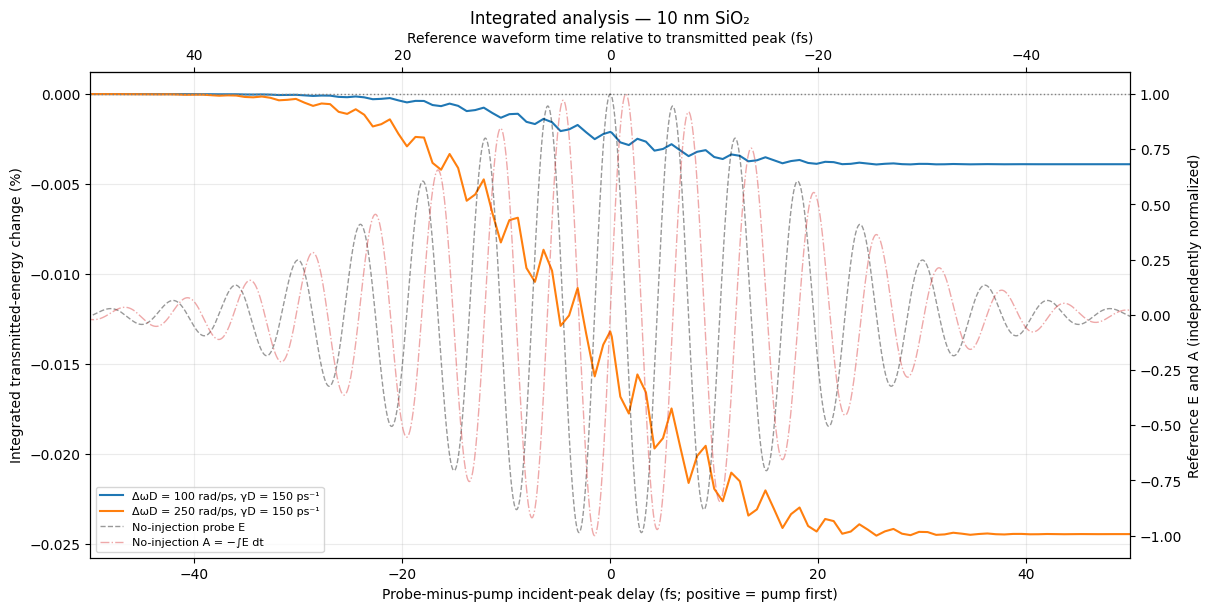

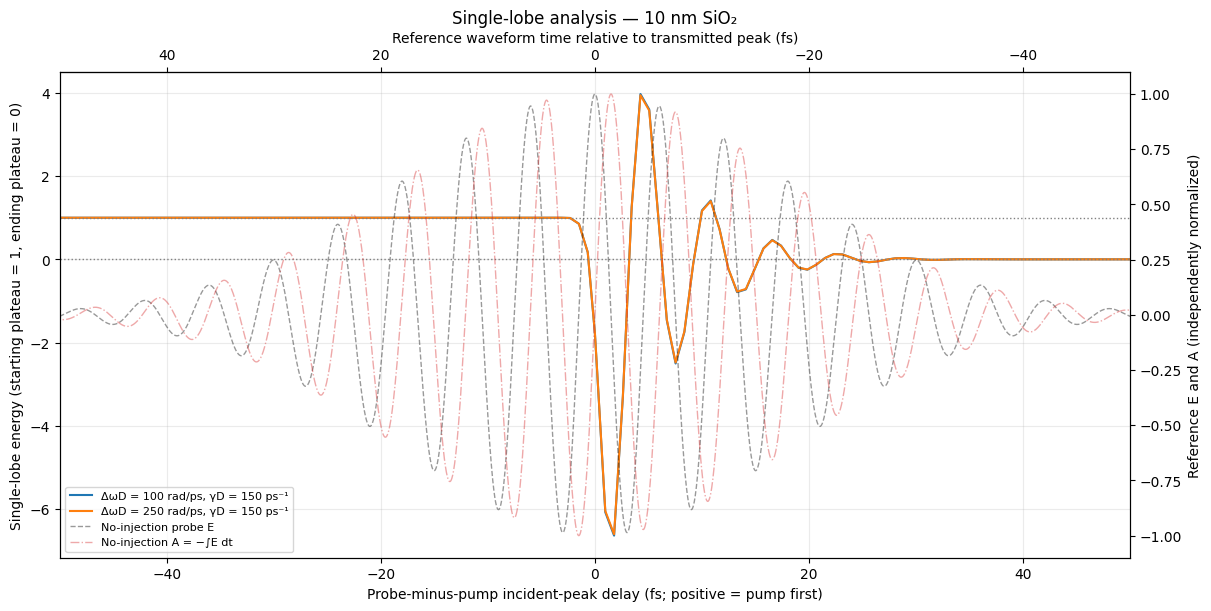

Saved analysis plots: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/thickness_10nm/stored_data_analysis


In [18]:
# STANDALONE STORED-DATA PLOTS: run this cell alone in a fresh kernel.
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

# ---- User controls ----
SAVED_SCAN_ROOT = None             # None: locate the thickness folder selected below; or Path("...")
THICKNESS_NM_TO_PLOT = 10.0       # 10.0, 1000.0, or 5000.0
PLOT_OUTPUT_SUBDIR = None         # None: stored_data_analysis/; runner selects raw/normalized folders
NORMALIZE_CONTINUA = False          # True: starting plateau = 1, ending plateau = 0
NORMALIZE_SINGLE_LOBE_CONTINUA = True  # Independent switch: lobe starting plateau = 1, ending = 0
PLOT_SINGLE_LOBE = True            # Include the single-lobe analysis plot
PLATEAU_POINTS = 5                # First/last N samples when a window below is None
START_PLATEAU_FS = None            # Optional inclusive (low, high), e.g. (None, -140.0)
END_PLATEAU_FS = None              # Optional inclusive (low, high), e.g. (45.0, None)
PLATEAU_SPREAD_TOLERANCE = 0.01     # Warn if plateau variation > 1% of the endpoint step
CENTRAL_VIEW_FS = (-50.0, 50.0)    # None disables the additional central-view figures
SHOW_REFERENCE_OVERLAYS = True
SAVE_STORED_PLOTS = True           # Write into stored_data_analysis/, preserving original analyses

if SAVED_SCAN_ROOT is None:
    _package = next((candidate for root in (Path.cwd(), *Path.cwd().parents)
                     for candidate in (root, root / "lightmatter")
                     if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None)
    if _package is None:
        raise FileNotFoundError("Set SAVED_SCAN_ROOT, or run from inside the lightmatter workspace.")
    saved_scan_root = (_package / "output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250"
                       / f"thickness_{THICKNESS_NM_TO_PLOT:g}nm")
else:
    saved_scan_root = Path(SAVED_SCAN_ROOT).expanduser().resolve()


def _saved_plateau_normalize(delay, ratio, points=5, start_window=None, end_window=None):
    """Affine normalization using the means of two explicitly selected endpoint regions."""
    delay, ratio = np.asarray(delay, float), np.asarray(ratio, float)
    if (delay.ndim != 1 or ratio.shape != delay.shape or delay.size < 2
            or not np.all(np.isfinite(delay)) or not np.all(np.isfinite(ratio))
            or np.any(np.diff(delay) <= 0)):
        raise ValueError("Need finite ratios on a strictly increasing delay axis.")
    if not isinstance(points, (int, np.integer)) or points < 1:
        raise ValueError("PLATEAU_POINTS must be a positive integer.")

    def select(window, at_start):
        if window is None:
            if 2*points > delay.size:
                raise ValueError("Too few delay samples for two non-overlapping endpoint regions.")
            return np.arange(points) if at_start else np.arange(delay.size-points, delay.size)
        if len(window) != 2:
            raise ValueError("A plateau window must be (low, high); use None for an open end.")
        low = -np.inf if window[0] is None else float(window[0])
        high = np.inf if window[1] is None else float(window[1])
        if np.isnan(low) or np.isnan(high) or low > high:
            raise ValueError("Invalid plateau window bounds.")
        indices = np.flatnonzero((delay >= low) & (delay <= high))
        if not indices.size:
            raise ValueError(f"No samples in plateau window {window}.")
        return indices

    start_ids, end_ids = select(start_window, True), select(end_window, False)
    if delay[start_ids[-1]] >= delay[end_ids[0]]:
        raise ValueError("Starting and ending plateau regions must be disjoint and ordered.")
    start, end = float(ratio[start_ids].mean()), float(ratio[end_ids].mean())
    step = start-end
    if abs(step) <= 1e-12*max(1.0, abs(start), abs(end)):
        raise ValueError("Endpoint levels are indistinguishable; continuum normalization is undefined.")
    spread = max(float(np.ptp(ratio[start_ids])), float(np.ptp(ratio[end_ids])))/abs(step)
    details = dict(start_level=start, end_level=end, step=step,
                   start_window_used_fs=delay[start_ids[[0, -1]]].tolist(),
                   end_window_used_fs=delay[end_ids[[0, -1]]].tolist(),
                   start_sample_count=int(start_ids.size), end_sample_count=int(end_ids.size),
                   maximum_plateau_spread_fraction_of_step=spread)
    # Do not clip: overshoots and undershoots remain visible.
    return (ratio-end)/step, details


def _saved_reference_overlay(ax, reference):
    time_s, field = reference["t_ps"]*1e-12, reference["E_t"]
    potential = -cumulative_trapezoid(field, time_s, initial=0.0)
    peak_time_s = time_s[np.argmax(abs(field))]
    twin = ax.twinx()
    for values, color, style, label in (
        (field, "black", "--", "No-injection probe E"),
        (potential, "C3", "-.", "No-injection A = −∫E dt"),
    ):
        scale = np.max(abs(values))
        if scale <= 0:
            raise ValueError("The saved reference field/vector potential is zero.")
        twin.plot((peak_time_s-time_s)*1e15, values/scale, color=color, ls=style,
                  lw=1, alpha=0.4, label=label)
    twin.set_ylabel("Reference E and A (independently normalized)")
    top = ax.secondary_xaxis("top", functions=(lambda x: -x, lambda x: -x))
    top.set_xlabel("Reference waveform time relative to transmitted peak (fs)")
    return twin


saved_cases = []
for case_dir in saved_scan_root.glob("del_omega_D_*_rad_per_ps"):
    config = json.loads((case_dir / "scan_configuration.json").read_text())
    manifest = json.loads((case_dir / "scan_manifest.json").read_text())
    rows = manifest["runs"]
    ids = [row["index"] for row in rows]
    if (not rows or not manifest.get("complete", False) or len(set(ids)) != len(ids)
            or set(manifest.get("completed_indices", [])) != set(ids)):
        raise ValueError(f"Incomplete or inconsistent saved scan: {case_dir}")
    expected_delays = np.sort(np.asarray([row["delay_fs"] for row in rows], dtype=float))
    if not np.all(np.isfinite(expected_delays)) or np.any(np.diff(expected_delays) <= 0):
        raise ValueError(f"Invalid saved delay axis: {case_dir}")

    def read_ratios(path, ratio_key):
        if not path.is_file():
            raise FileNotFoundError(f"Missing {path}. Run the analysis-only helper cells to rebuild it from saved traces.")
        with np.load(path, allow_pickle=False) as archive:
            delay, ratio = np.asarray(archive["delay_fs"], float), np.asarray(archive[ratio_key], float)
        if delay.ndim != 1 or ratio.shape != delay.shape or not np.all(np.isfinite(ratio)):
            raise ValueError(f"Invalid analysis arrays: {path}")
        order = np.argsort(delay)
        delay, ratio = delay[order], ratio[order]
        if delay.shape != expected_delays.shape or not np.allclose(delay, expected_delays, rtol=0, atol=1e-9):
            raise ValueError(f"Analysis delays do not match the completed manifest: {path}")
        return delay, ratio

    delay, ratio = read_ratios(case_dir / "delay_scan_analysis.npz", "transmitted_energy_ratio")
    with np.load(case_dir / "unpumped_reference/data.npz", allow_pickle=False) as archive:
        reference = {key: np.asarray(archive[key], float) for key in ("t_ps", "E_t")}
    if (reference["t_ps"].ndim != 1 or reference["E_t"].shape != reference["t_ps"].shape
            or not all(np.all(np.isfinite(a)) for a in reference.values())
            or np.any(np.diff(reference["t_ps"]) <= 0)):
        raise ValueError(f"Invalid reference waveform: {case_dir}")
    case = dict(directory=case_dir, delta=float(config["del_omega_D_rad_per_ps"]),
                gamma=float(config["gamma_D_per_ps"]),
                thickness_nm=float(config.get("material_thickness_nm",
                    (config["fdtd_params"]["metal_i1"]-config["fdtd_params"]["metal_i0"])*config["fdtd_params"]["dz"]/10.0)),
                delay_fs=delay, ratio=ratio, reference=reference)
    if NORMALIZE_CONTINUA:
        case["integrated_display"], case["plateaus"] = _saved_plateau_normalize(
            delay, ratio, PLATEAU_POINTS, START_PLATEAU_FS, END_PLATEAU_FS)
        if case["plateaus"]["maximum_plateau_spread_fraction_of_step"] > PLATEAU_SPREAD_TOLERANCE:
            warnings.warn(f"ΔωD={case['delta']:g}: chosen endpoint regions are not flat to the requested tolerance; adjust plateau windows.")
        print(f"ΔωD={case['delta']:g}: start={case['plateaus']['start_level']:.9f} → 1; "
              f"end={case['plateaus']['end_level']:.9f} → 0")
    else:
        case["integrated_display"] = 100*(ratio-1)
    if PLOT_SINGLE_LOBE:
        case["lobe_delay_fs"], case["lobe_ratio"] = read_ratios(
            case_dir / "single_lobe_analysis/lobe_energy_analysis.npz", "ratio")
        if NORMALIZE_SINGLE_LOBE_CONTINUA:
            case["lobe_display"], case["lobe_plateaus"] = _saved_plateau_normalize(
                case["lobe_delay_fs"], case["lobe_ratio"],
                PLATEAU_POINTS, START_PLATEAU_FS, END_PLATEAU_FS)
            if case["lobe_plateaus"]["maximum_plateau_spread_fraction_of_step"] > PLATEAU_SPREAD_TOLERANCE:
                warnings.warn(f"Single lobe, ΔωD={case['delta']:g}: chosen endpoint regions are not flat to the requested tolerance; adjust plateau windows.")
            print(f"Single lobe, ΔωD={case['delta']:g}: start={case['lobe_plateaus']['start_level']:.9f} → 1; "
                  f"end={case['lobe_plateaus']['end_level']:.9f} → 0")
        else:
            case["lobe_display"] = case["lobe_ratio"].copy()
    saved_cases.append(case)
if not saved_cases:
    raise FileNotFoundError(f"No saved parameter cases found in {saved_scan_root}.")
saved_cases.sort(key=lambda case: (case["gamma"], case["delta"]))
if SHOW_REFERENCE_OVERLAYS and any(
    not all(np.array_equal(case["reference"][key], saved_cases[0]["reference"][key]) for key in ("t_ps", "E_t"))
    for case in saved_cases[1:]
):
    raise ValueError("Cases have different no-injection references; plot them separately or disable reference overlays.")

saved_plot_dir = saved_scan_root / (PLOT_OUTPUT_SUBDIR or "stored_data_analysis")
if SAVE_STORED_PLOTS:
    saved_plot_dir.mkdir(parents=True, exist_ok=True)
mode = "continuum_normalized" if NORMALIZE_CONTINUA else "energy_change_percent"
plot_specs = [("integrated", f"integrated_{mode}",
               "Integrated energy (starting plateau = 1, ending plateau = 0)" if NORMALIZE_CONTINUA else "Integrated transmitted-energy change (%)")]
if PLOT_SINGLE_LOBE:
    lobe_mode = "continuum_normalized" if NORMALIZE_SINGLE_LOBE_CONTINUA else "energy_ratio"
    plot_specs.append(("single_lobe", f"single_lobe_{lobe_mode}",
                       "Single-lobe energy (starting plateau = 1, ending plateau = 0)"
                       if NORMALIZE_SINGLE_LOBE_CONTINUA else "Single-lobe energy ratio (pumped / unpumped)"))
saved_analysis_figures = {}
for kind, stem, ylabel in plot_specs:
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    for case in saved_cases:
        x = case["delay_fs"] if kind == "integrated" else case["lobe_delay_fs"]
        y = case["integrated_display"] if kind == "integrated" else case["lobe_display"]
        ax.plot(x, y, label=f"ΔωD = {case['delta']:g} rad/ps, γD = {case['gamma']:g} ps⁻¹")
    continuum_normalized = NORMALIZE_CONTINUA if kind == "integrated" else NORMALIZE_SINGLE_LOBE_CONTINUA
    baselines = (0, 1) if continuum_normalized else ((0,) if kind == "integrated" else (1,))
    for baseline in baselines:
        ax.axhline(baseline, color="0.5", ls=":", lw=1)
    ax.set(xlabel="Probe-minus-pump incident-peak delay (fs; positive = pump first)", ylabel=ylabel,
           title=("Integrated analysis" if kind == "integrated" else "Single-lobe analysis")
                 + f" — {saved_cases[0]['thickness_nm']:g} nm SiO₂",
           xlim=(min(c["delay_fs"][0] for c in saved_cases), max(c["delay_fs"][-1] for c in saved_cases)))
    ax.grid(alpha=0.25)
    lines, labels = ax.get_legend_handles_labels()
    if SHOW_REFERENCE_OVERLAYS:
        twin = _saved_reference_overlay(ax, saved_cases[0]["reference"])
        extra_lines, extra_labels = twin.get_legend_handles_labels()
        lines += extra_lines; labels += extra_labels
    ax.legend(lines, labels, fontsize=8, loc="lower left")
    if SAVE_STORED_PLOTS:
        for extension in ("png", "pdf"):
            fig.savefig(saved_plot_dir / f"{stem}.{extension}", dpi=180)
        if CENTRAL_VIEW_FS is not None:
            full_limits = ax.get_xlim()
            ax.set_xlim(CENTRAL_VIEW_FS)
            for extension in ("png", "pdf"):
                fig.savefig(saved_plot_dir / f"{stem}_central.{extension}", dpi=180)
            # ax.set_xlim(full_limits)
            ax.set_xlim((-50,50))
    saved_analysis_figures[kind] = fig
    plt.show()

if SAVE_STORED_PLOTS and NORMALIZE_CONTINUA:
    for case in saved_cases:
        np.savez_compressed(saved_plot_dir / f"{case['directory'].name}_continuum_normalized.npz",
                            delay_fs=case["delay_fs"], original_integrated_ratio=case["ratio"],
                            normalized_integrated_ratio=case["integrated_display"])
    (saved_plot_dir / "continuum_normalization.json").write_text(json.dumps(dict(
        formula="(R - mean(end plateau)) / (mean(start plateau) - mean(end plateau))",
        plateau_points=PLATEAU_POINTS, requested_start_window_fs=START_PLATEAU_FS,
        requested_end_window_fs=END_PLATEAU_FS,
        cases=[dict(directory=c["directory"].name, **c["plateaus"]) for c in saved_cases]), indent=2))
if SAVE_STORED_PLOTS and PLOT_SINGLE_LOBE and NORMALIZE_SINGLE_LOBE_CONTINUA:
    for case in saved_cases:
        np.savez_compressed(saved_plot_dir / f"{case['directory'].name}_single_lobe_continuum_normalized.npz",
                            delay_fs=case["lobe_delay_fs"], original_lobe_ratio=case["lobe_ratio"],
                            normalized_lobe_ratio=case["lobe_display"])
    (saved_plot_dir / "single_lobe_continuum_normalization.json").write_text(json.dumps(dict(
        formula="(R_lobe - mean(end plateau)) / (mean(start plateau) - mean(end plateau))",
        plateau_points=PLATEAU_POINTS, requested_start_window_fs=START_PLATEAU_FS,
        requested_end_window_fs=END_PLATEAU_FS,
        cases=[dict(directory=c["directory"].name, **c["lobe_plateaus"]) for c in saved_cases]), indent=2))
if SAVE_STORED_PLOTS:
    print("Saved analysis plots:", saved_plot_dir)


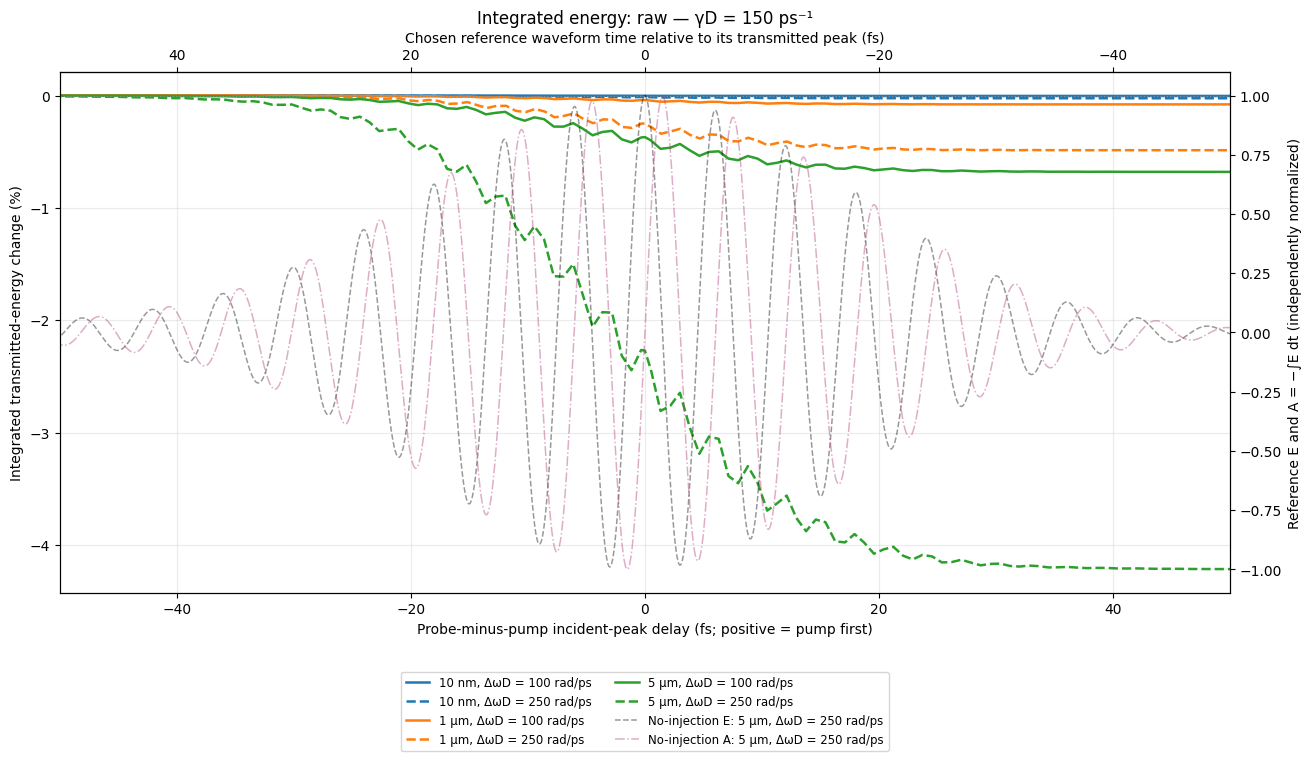

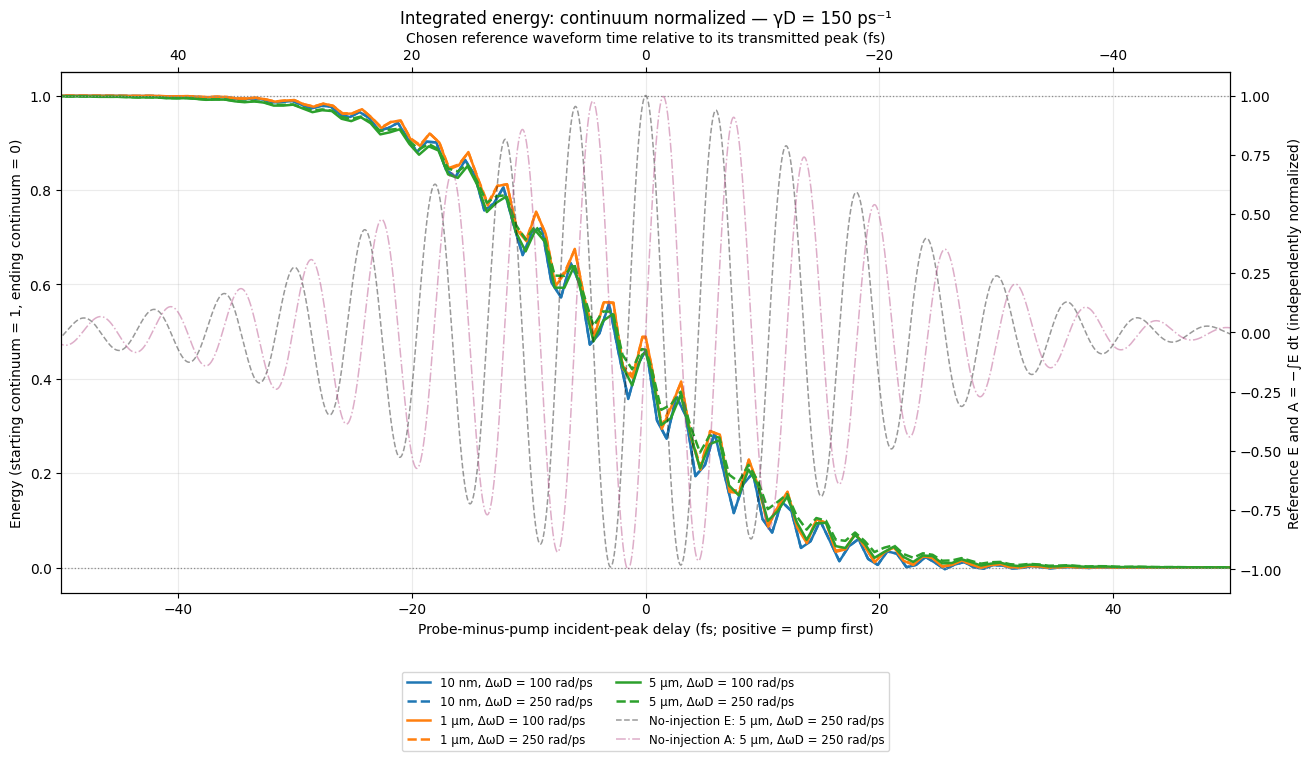

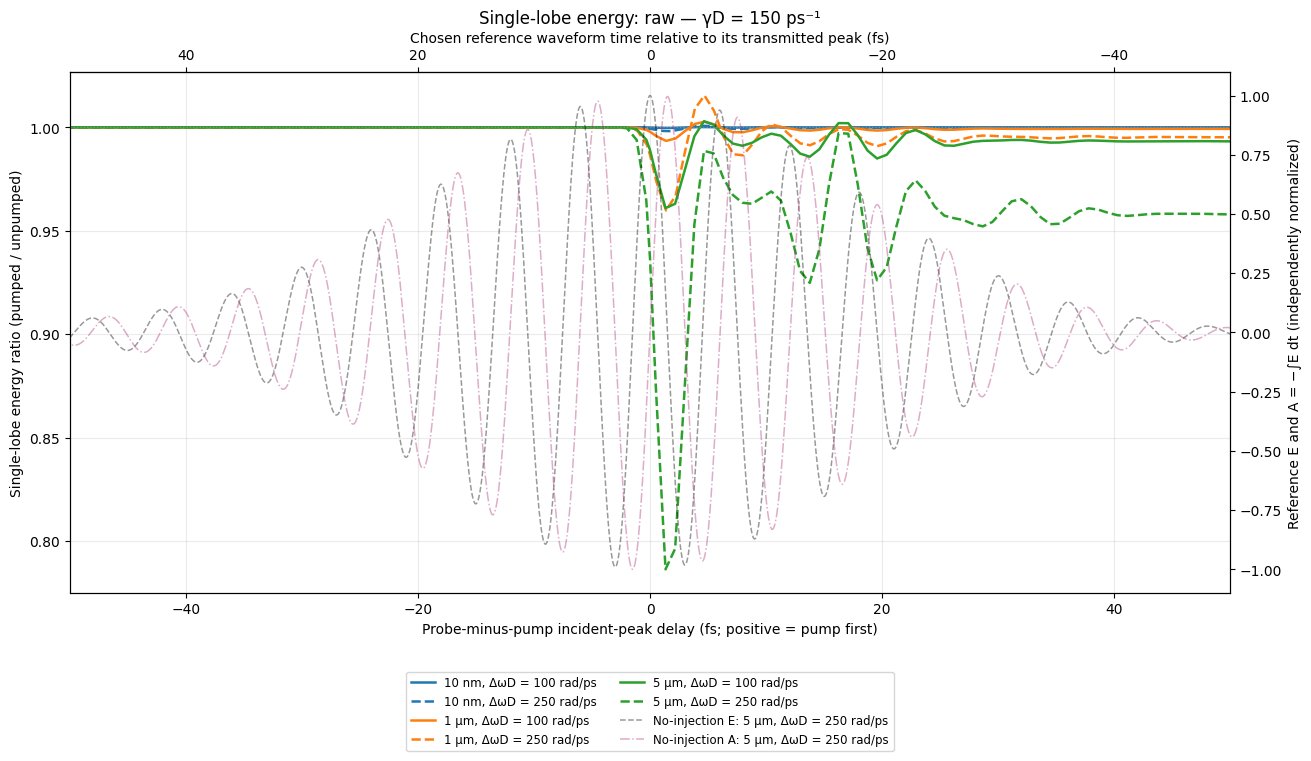

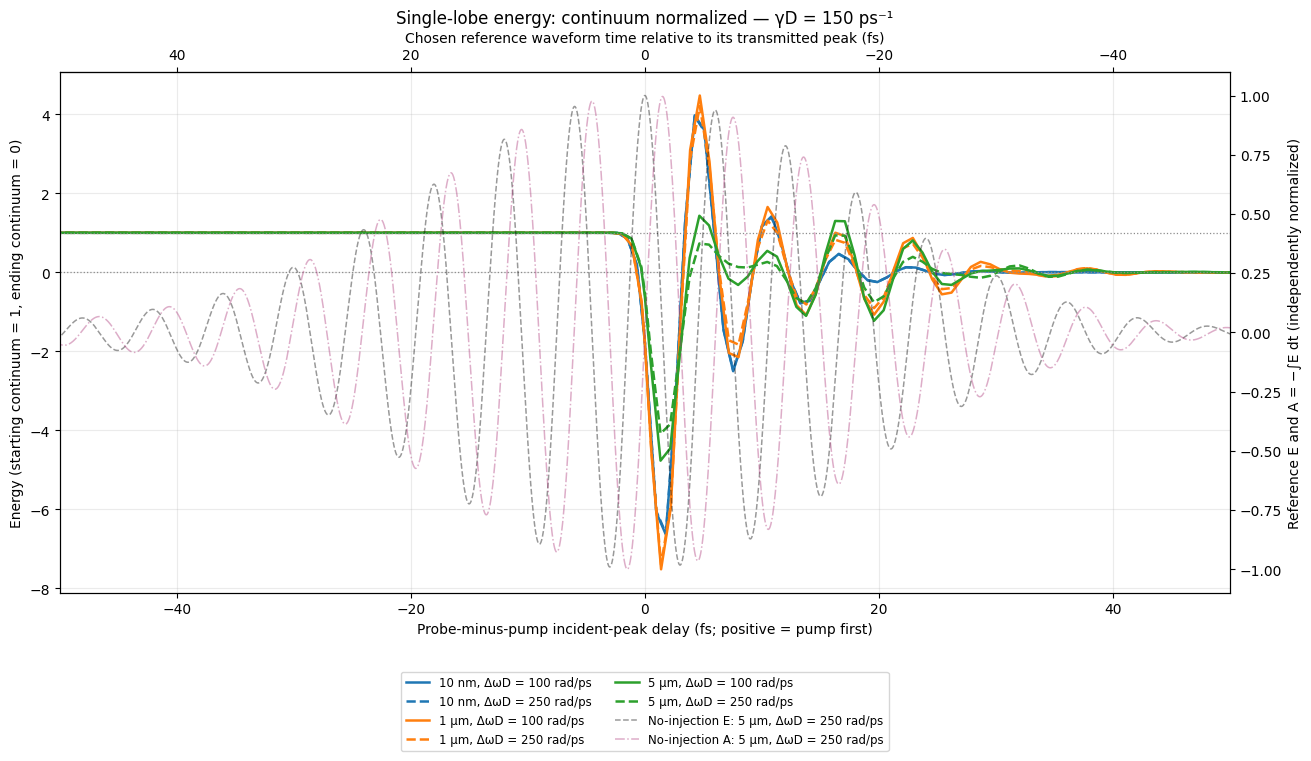

Saved all six scenarios, four comparison plots, and numerical arrays to: /home/arch/MSC_studies/spring_26/semester_project/lightmatter/output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250/all_scenarios_analysis/reference_5000nm_del_omega_D_250


In [21]:
# ALL SIX SCENARIOS — standalone saved-data comparison; no simulation cells required.
# Produces raw and continuum-normalized integrated and single-lobe plots.
# Each curve uses its own saved delay grid and endpoint plateau means.
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

# ---- User controls ----
ALL_SCENARIOS_DATA_DIR = None      # None: locate the thickness-sweep directory; or Path("...")
REFERENCE_THICKNESS_NM = 5000.0    # Overlay reference: 10.0, 1000.0, or 5000.0 nm
REFERENCE_DEL_OMEGA_D = 250.0      # Overlay reference: 100.0 or 250.0 rad/ps
ALL_PLATEAU_POINTS = 5            # First/last N samples unless explicit windows are supplied
ALL_START_PLATEAU_FS = None       # Inclusive (low, high); None at a boundary means unbounded
ALL_END_PLATEAU_FS = None         # Example: (45.0, None)
ALL_PLATEAU_SPREAD_TOLERANCE = 0.01  # Warn if plateau variation exceeds 1% of its endpoint step
ALL_CENTRAL_VIEW_FS = (-50.0, 50.0)  # Also save/show this detail; None shows only the full range
SAVE_ALL_SCENARIO_PLOTS = True

if ALL_SCENARIOS_DATA_DIR is None:
    _all_package = next((candidate for root in (Path.cwd(), *Path.cwd().parents)
                         for candidate in (root, root / "lightmatter")
                         if (candidate / "src/lightmatter/fdtd_revised_sio2.py").is_file()), None)
    if _all_package is None:
        raise FileNotFoundError("Set ALL_SCENARIOS_DATA_DIR, or run from inside the lightmatter workspace.")
    all_scenarios_root = _all_package / "output/project2/forward_model_checks/gaussian_probe_166THz_30fs_gamma_D0_150_thickness_10nm_1um_5um_del_omega_D_100_250"
else:
    all_scenarios_root = Path(ALL_SCENARIOS_DATA_DIR).expanduser().resolve()


def _all_thickness_label(thickness_nm):
    return f"{thickness_nm:g} nm" if thickness_nm < 1000 else f"{thickness_nm/1000:g} µm"


def _all_normalize_continua(delay, ratio):
    """Map the selected starting and ending plateau MEANS to 1 and 0; no clipping."""
    if not isinstance(ALL_PLATEAU_POINTS, (int, np.integer)) or ALL_PLATEAU_POINTS < 1:
        raise ValueError("ALL_PLATEAU_POINTS must be a positive integer.")

    def select(window, at_start):
        if window is None:
            if 2*ALL_PLATEAU_POINTS > delay.size:
                raise ValueError("Too few samples for two disjoint endpoint regions.")
            return (np.arange(ALL_PLATEAU_POINTS) if at_start
                    else np.arange(delay.size-ALL_PLATEAU_POINTS, delay.size))
        if len(window) != 2:
            raise ValueError("Plateau windows must be (low, high).")
        low = -np.inf if window[0] is None else float(window[0])
        high = np.inf if window[1] is None else float(window[1])
        if np.isnan(low) or np.isnan(high) or low > high:
            raise ValueError("Invalid plateau-window bounds.")
        indices = np.flatnonzero((delay >= low) & (delay <= high))
        if not indices.size:
            raise ValueError(f"No samples in plateau window {window}.")
        return indices

    first = select(ALL_START_PLATEAU_FS, True)
    last = select(ALL_END_PLATEAU_FS, False)
    if delay[first[-1]] >= delay[last[0]]:
        raise ValueError("Starting and ending plateau regions must be disjoint and ordered.")
    start_level, end_level = float(ratio[first].mean()), float(ratio[last].mean())
    step = start_level-end_level
    if abs(step) <= 1e-12*max(1.0, abs(start_level), abs(end_level)):
        raise ValueError("Endpoint levels are indistinguishable; normalization is undefined.")
    spread = max(float(np.ptp(ratio[first])), float(np.ptp(ratio[last])))/abs(step)
    metadata = dict(start_level=start_level, end_level=end_level, step=step,
                    start_window_used_fs=delay[first[[0, -1]]].tolist(),
                    end_window_used_fs=delay[last[[0, -1]]].tolist(),
                    start_sample_count=int(first.size), end_sample_count=int(last.size),
                    maximum_plateau_spread_fraction_of_step=spread)
    return (ratio-end_level)/step, metadata


all_scenario_cases = []
for thickness_nm in (10.0, 1000.0, 5000.0):
    for delta in (100.0, 250.0,):
        case_dir = all_scenarios_root / f"thickness_{thickness_nm:g}nm" / f"del_omega_D_{delta:g}_rad_per_ps"
        configuration = json.loads((case_dir / "scan_configuration.json").read_text())
        manifest = json.loads((case_dir / "scan_manifest.json").read_text())
        rows = manifest["runs"]
        indices = [row["index"] for row in rows]
        if (not rows or not manifest.get("complete", False) or len(set(indices)) != len(indices)
                or set(manifest.get("completed_indices", [])) != set(indices)):
            raise ValueError(f"Incomplete or inconsistent scan: {case_dir}")
        actual_nm = ((configuration["fdtd_params"]["metal_i1"]-configuration["fdtd_params"]["metal_i0"])
                     * configuration["fdtd_params"]["dz"]/10.0)
        if not (np.isclose(actual_nm, thickness_nm)
                and np.isclose(configuration["del_omega_D_rad_per_ps"], delta)
                and np.isclose(configuration["gamma_D_per_ps"], 150.0)):
            raise ValueError(f"Saved configuration does not match the requested scenario: {case_dir}")
        expected_delays = np.sort(np.asarray([row["delay_fs"] for row in rows], float))
        if not np.all(np.isfinite(expected_delays)) or np.any(np.diff(expected_delays) <= 0):
            raise ValueError(f"Invalid manifest delay axis: {case_dir}")
        case = dict(directory=case_dir, thickness_nm=thickness_nm, delta=delta,
                    label=f"{_all_thickness_label(thickness_nm)}, ΔωD = {delta:g} rad/ps")
        for kind, relative_path, ratio_key in (
            ("integrated", "delay_scan_analysis.npz", "transmitted_energy_ratio"),
            ("single_lobe", "single_lobe_analysis/lobe_energy_analysis.npz", "ratio"),
        ):
            with np.load(case_dir / relative_path, allow_pickle=False) as archive:
                delay, ratio = np.asarray(archive["delay_fs"], float), np.asarray(archive[ratio_key], float)
            if delay.ndim != 1 or ratio.shape != delay.shape or not np.all(np.isfinite(ratio)):
                raise ValueError(f"Invalid {kind} arrays: {case_dir}")
            order = np.argsort(delay)
            delay, ratio = delay[order], ratio[order]
            if delay.shape != expected_delays.shape or not np.allclose(delay, expected_delays, rtol=0, atol=1e-9):
                raise ValueError(f"Saved {kind} delays disagree with the manifest: {case_dir}")
            values, plateaus = _all_normalize_continua(delay, ratio)
            if plateaus["maximum_plateau_spread_fraction_of_step"] > ALL_PLATEAU_SPREAD_TOLERANCE:
                warnings.warn(f"{case['label']} ({kind}): endpoint regions are not flat to the selected tolerance; adjust plateau windows.")
            case[kind] = dict(delay_fs=delay, ratio=ratio, normalized=values, plateaus=plateaus)
        all_scenario_cases.append(case)

# Select exactly one saved no-injection waveform for BOTH analyses and BOTH modes.
reference_matches = [case for case in all_scenario_cases
                     if np.isclose(case["thickness_nm"], REFERENCE_THICKNESS_NM)
                     and np.isclose(case["delta"], REFERENCE_DEL_OMEGA_D)]
if len(reference_matches) != 1:
    raise ValueError("Choose a reference from the six thickness/ΔωD scenarios listed above.")
all_reference_case = reference_matches[0]
all_reference_dir = all_reference_case["directory"] / "unpumped_reference"
reference_info = json.loads((all_reference_dir / "info.json").read_text())
if reference_info.get("material_state") != "unpumped":
    raise ValueError("The overlay must use a no-injection reference.")
with np.load(all_reference_dir / "data.npz", allow_pickle=False) as archive:
    all_reference_time_s = np.asarray(archive["t_ps"], float)*1e-12
    all_reference_field = np.asarray(archive["E_t"], float)
if (all_reference_time_s.ndim != 1 or all_reference_time_s.size < 3
        or all_reference_field.shape != all_reference_time_s.shape
        or not np.all(np.isfinite(all_reference_time_s)) or not np.all(np.isfinite(all_reference_field))
        or np.any(np.diff(all_reference_time_s) <= 0) or np.max(abs(all_reference_field)) <= 0):
    raise ValueError("Invalid saved no-injection waveform.")
# Integrate in increasing physical time before mapping onto the delay display axis.
all_reference_potential = -cumulative_trapezoid(all_reference_field, all_reference_time_s, initial=0.0)
all_reference_peak_s = float(all_reference_time_s[np.argmax(abs(all_reference_field))])
all_reference_delay_fs = (all_reference_peak_s-all_reference_time_s)*1e15
# This peak-aligned overlay is a timing guide; none of the six delay grids is shifted.
all_reference_label = all_reference_case["label"]
all_comparison_output = (all_scenarios_root / "all_scenarios_analysis"
                         / f"reference_{REFERENCE_THICKNESS_NM:g}nm_del_omega_D_{REFERENCE_DEL_OMEGA_D:g}")
if SAVE_ALL_SCENARIO_PLOTS:
    all_comparison_output.mkdir(parents=True, exist_ok=True)

all_comparison_figures = {}
for kind, title in (("integrated", "Integrated energy"), ("single_lobe", "Single-lobe energy")):
    for normalized in (False, True):
        mode = "continuum_normalized" if normalized else "raw"
        fig, ax = plt.subplots(figsize=(13, 7.5), constrained_layout=True)
        for case in all_scenario_cases:
            result = case[kind]
            values = (result["normalized"] if normalized else
                      (100*(result["ratio"]-1) if kind == "integrated" else result["ratio"]))
            color = {10.0: "C0", 1000.0: "C1", 5000.0: "C2"}[case["thickness_nm"]]
            style = "-" if case["delta"] == 100.0 else "--"
            ax.plot(result["delay_fs"], values, color=color, ls=style, lw=1.8, label=case["label"])
        for baseline in ((0, 1) if normalized else ((0,) if kind == "integrated" else (1,))):
            ax.axhline(baseline, color="0.55", ls=":", lw=0.9)
        ylabel = ("Energy (starting continuum = 1, ending continuum = 0)" if normalized else
                  ("Integrated transmitted-energy change (%)" if kind == "integrated" else "Single-lobe energy ratio (pumped / unpumped)"))
        ax.set(xlabel="Probe-minus-pump incident-peak delay (fs; positive = pump first)", ylabel=ylabel,
               title=f"{title}: {'continuum normalized' if normalized else 'raw'} — γD = 150 ps⁻¹",
               xlim=(min(c[kind]["delay_fs"][0] for c in all_scenario_cases),
                     max(c[kind]["delay_fs"][-1] for c in all_scenario_cases)))
        ax.grid(alpha=0.25)
        overlay = ax.twinx()
        for values, color, style, label in (
            (all_reference_field, "black", "--", f"No-injection E: {all_reference_label}"),
            (all_reference_potential, "#aa3377", "-.", f"No-injection A: {all_reference_label}"),
        ):
            scale = np.max(abs(values))
            if scale <= 0:
                raise ValueError("Cannot display-normalize a zero reference field/vector potential.")
            overlay.plot(all_reference_delay_fs, values/scale, color=color, ls=style,
                         lw=1.1, alpha=0.4, label=label)
        overlay.set_ylabel("Reference E and A = −∫E dt (independently normalized)")
        top = ax.secondary_xaxis("top", functions=(lambda x: -x, lambda x: -x))
        top.set_xlabel("Chosen reference waveform time relative to its transmitted peak (fs)")
        handles, labels = ax.get_legend_handles_labels()
        overlay_handles, overlay_labels = overlay.get_legend_handles_labels()
        ax.legend(handles+overlay_handles, labels+overlay_labels, loc="upper center",
                  bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8.5)
        stem = f"all_scenarios_{kind}_{mode}"
        if SAVE_ALL_SCENARIO_PLOTS:
            for extension in ("png", "pdf"):
                fig.savefig(all_comparison_output / f"{stem}.{extension}", dpi=180)
        if ALL_CENTRAL_VIEW_FS is not None:
            ax.set_xlim(ALL_CENTRAL_VIEW_FS)
            if SAVE_ALL_SCENARIO_PLOTS:
                for extension in ("png", "pdf"):
                    fig.savefig(all_comparison_output / f"{stem}_central.{extension}", dpi=180)
        all_comparison_figures[(kind, mode)] = fig
        plt.show()

if SAVE_ALL_SCENARIO_PLOTS:
    for case in all_scenario_cases:
        np.savez_compressed(all_comparison_output / f"thickness_{case['thickness_nm']:g}nm_del_omega_D_{case['delta']:g}_analyses.npz",
                            integrated_delay_fs=case["integrated"]["delay_fs"],
                            integrated_ratio=case["integrated"]["ratio"],
                            integrated_normalized=case["integrated"]["normalized"],
                            lobe_delay_fs=case["single_lobe"]["delay_fs"],
                            lobe_ratio=case["single_lobe"]["ratio"],
                            lobe_normalized=case["single_lobe"]["normalized"])
    (all_comparison_output / "comparison_metadata.json").write_text(json.dumps(dict(
        reference_case=str(all_reference_case["directory"]),
        reference_thickness_nm=REFERENCE_THICKNESS_NM, reference_del_omega_D_rad_per_ps=REFERENCE_DEL_OMEGA_D,
        reference_peak_time_s=all_reference_peak_s,
        overlay_coordinate="reference transmitted abs(E) peak time minus waveform time; timing guide only",
        delay_definition="probe minus pump incident-peak time; positive = pump first; no per-case shifts",
        normalization="(R - mean(end plateau)) / (mean(start plateau) - mean(end plateau)), independently for each case and analysis",
        plateau_points=ALL_PLATEAU_POINTS, requested_start_window_fs=ALL_START_PLATEAU_FS,
        requested_end_window_fs=ALL_END_PLATEAU_FS,
        cases=[dict(thickness_nm=c["thickness_nm"], del_omega_D_rad_per_ps=c["delta"],
                    integrated_plateaus=c["integrated"]["plateaus"],
                    single_lobe_plateaus=c["single_lobe"]["plateaus"]) for c in all_scenario_cases]), indent=2))
    print("Saved all six scenarios, four comparison plots, and numerical arrays to:", all_comparison_output)
